# Retail Analytics – Where Is Profit Leaking?
**Course project | Python | Exploratory Data Analysis and Statistical Analysis**

## Project objective
Investigate sales and profitability patterns, identify areas associated with lower profit, and develop evidence-based business recommendations.

**Main research question:** Where is profit leaking in the retail business, and which factors are associated with reduced profitability?

### Supporting questions
1. **Descriptive:** Which sales channels, customer segments, countries/regions and products have the highest and lowest sales and profit?
2. **Diagnostic:** How are discounts, returns, delivery performance and marketing channels associated with profit?
3. **Recommendation:** What practical actions could improve profitability?

## Important analysis rules
- Keep the original CSV files unchanged. All cleaning is performed on working copies.
- The sales file has one row per order according to its structure, while `order_items.csv` has multiple rows per order. Do not join them directly without checking the resulting row counts: this can duplicate order-level values.
- Monetary values occur in multiple currencies. **Do not add different currencies together.** Analyse amounts by currency unless a verified exchange-rate table and conversion date are supplied. The order-items file has no currency field, so currency must be attached from the sales table using `order_id` before item-level financial analysis.
- `dataset_statistics.csv` is a supplied summary. Treat its figures as reported values and verify them against the raw files.
- A relationship or correlation does not prove causation.
- The datasets contain customer names and reviews. Do not publish personally identifying customer details in the report or presentation.

## 1. Project folder setup

```text
Retail_Analytics_Project/
├── data/
│   ├── customer_master.csv
│   ├── dataset_statistics.csv
│   ├── ecommerce_sales_customer_analytics_150k.csv
│   ├── order_items.csv
│   └── product_catalog.csv
├── outputs/
└── retail_analytics.ipynb
```


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("datasets")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

FILES = {
    "customers": DATA_DIR / "customer_master.csv",
    "statistics": DATA_DIR / "dataset_statistics.csv",
    "sales": DATA_DIR / "ecommerce_sales_customer_analytics_150k.csv",
    "order_items": DATA_DIR / "order_items.csv",
    "products": DATA_DIR / "product_catalog.csv",
}

for name, path in FILES.items():
    print(f"{name:12} | exists: {path.exists()} | {path}")

customers    | exists: False | datasets\customer_master.csv
statistics   | exists: False | datasets\dataset_statistics.csv
sales        | exists: False | datasets\ecommerce_sales_customer_analytics_150k.csv
order_items  | exists: False | datasets\order_items.csv
products     | exists: False | datasets\product_catalog.csv


## 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the five datasets

In [3]:
# Resolve the datasets folder robustly
base_dir = Path.cwd()
candidate_dirs = [
    base_dir,
    base_dir / "datasets",
    base_dir.parent / "datasets",
    Path(r"C:\Users\sarat\Desktop\Final\datasets"),  # adjust if needed
]

file_names = {
    "customers": "customer_master.csv",
    "statistics": "dataset_statistics.csv",
    "sales": "ecommerce_sales_customer_analytics_150k.csv",
    "order_items": "order_items.csv",
    "products": "product_catalog.csv",
}

resolved_files = {}
for name, filename in file_names.items():
    path = next(
        (directory / filename for directory in candidate_dirs
         if directory.is_dir() and (directory / filename).is_file()),
        None
    )
    if path is None:
        path = next(
            (match for directory in candidate_dirs if directory.is_dir()
             for match in directory.rglob(filename)),
            None
        )
    if path is None:
        raise FileNotFoundError(
            f"Could not find {filename}. Place it in the project folder or datasets folder."
        )
    resolved_files[name] = path

FILES = resolved_files
DATA_DIR = next(iter(FILES.values())).parent

customers = pd.read_csv(FILES["customers"])
statistics_summary = pd.read_csv(FILES["statistics"])
sales = pd.read_csv(FILES["sales"])
order_items = pd.read_csv(FILES["order_items"])
products = pd.read_csv(FILES["products"])

print("All five datasets loaded.")
print("Dataset file locations:", FILES)

All five datasets loaded.
Dataset file locations: {'customers': WindowsPath('c:/Users/SURFACE/OneDrive/Desktop/Retail_Analytics/Data/customer_master.csv'), 'statistics': WindowsPath('c:/Users/SURFACE/OneDrive/Desktop/Retail_Analytics/Data/dataset_statistics.csv'), 'sales': WindowsPath('c:/Users/SURFACE/OneDrive/Desktop/Retail_Analytics/Data/ecommerce_sales_customer_analytics_150k.csv'), 'order_items': WindowsPath('c:/Users/SURFACE/OneDrive/Desktop/Retail_Analytics/Data/order_items.csv'), 'products': WindowsPath('c:/Users/SURFACE/OneDrive/Desktop/Retail_Analytics/Data/product_catalog.csv')}


## 4. Dataset dimensions and preview

In [4]:
dataframes = {
    "customers": customers,
    "statistics_summary": statistics_summary,
    "sales": sales,
    "order_items": order_items,
    "products": products,
}

overview = pd.DataFrame([
    {"Dataset": name, "Rows": df.shape[0], "Columns": df.shape[1]}
    for name, df in dataframes.items()
])
display(overview)

for name, df in dataframes.items():
    print(f"\n{name.upper()} – first 5 rows")
    display(df.head())

,Dataset,Rows,Columns
0,customers,25000,11
1,statistics_summary,1,11
2,sales,138116,46
3,order_items,397569,12
4,products,1175,9



CUSTOMERS – first 5 rows


,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34



STATISTICS_SUMMARY – first 5 rows


,Total Transactions,Total Columns,Total Customers,Total Products Used,Date Range,Total Revenue,Total Profit,Average Order Value,Average Rating,Return Rate,Cancellation Rate
0,138116,46,24911,138116,2021-01-01 to 2025-12-31,"$177,134,263.74","$76,146,395.76","$1,282.50",3.68,6.85%,6.08%



SALES – first 5 rows


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.00,3.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,"1,350.19",477.89,61.07,12.03,945.40,588.33,345.04,36.50,"12,459.68",True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.00,10.00,On Time,NaN,NaN,3.60,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,"3,144.64","1,456.06",320.83,9.00,"2,018.41","2,031.88",-22.47,-1.11,"13,032.48",True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.00,3.00,On Time,NaN,NaN,4.30,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,"6,159.44",True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,66329,Debit Card,Paid,USD,Express,WH-010,2.00,2.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Email Marketing,NaN,NaN,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,"5,638.30",True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,77306,Digital Wallet,Paid,INR,Standard,WH-013,6.00,5.00,Delayed,NaN,NaN,3.00,Neutral,Mixed feelings about this purchase.,Direct,NaN,NaN,278,147,6,"2,474.52",133.63,421.35,23.03,"2,785.27","1,231.88","1,530.36",54.94,"13,240.10",True,8



ORDER_ITEMS – first 5 rows


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.34,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.36,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.47,"1,413.89","3,019.20",305.01,9.00,"1,919.32","1,976.16",-65.84
3,ORD-773460,PROD-000268,4,31.36,0.34,42.17,125.44,15.82,0.00,99.09,55.72,43.37
4,ORD-449374,PROD-001040,3,6.31,0.09,1.70,18.93,1.21,0.98,19.42,5.91,12.53



PRODUCTS – first 5 rows


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.30
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.90
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.90
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,"1,120.49",564.86,4.80
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,"1,282.18",695.54,2.90


## 5. Column names and data types

In [16]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    display(pd.DataFrame({
        "column": df.columns,
        "data_type": df.dtypes.astype(str).values,
        "non_null": df.notna().sum().values,
        "missing": df.isna().sum().values,
    }))


CUSTOMERS


,column,data_type,non_null,missing
0,customer_id,str,25000,0
1,customer_name,str,25000,0
2,customer_age,int64,25000,0
3,gender,str,25000,0
4,customer_segment,str,25000,0
5,customer_city,str,25000,0
6,customer_state,str,25000,0
7,customer_country,str,25000,0
8,region,str,25000,0
9,customer_postal_code,int64,25000,0



STATISTICS_SUMMARY


,column,data_type,non_null,missing
0,Total Transactions,int64,1,0
1,Total Columns,int64,1,0
2,Total Customers,int64,1,0
3,Total Products Used,int64,1,0
4,Date Range,str,1,0
5,Total Revenue,str,1,0
6,Total Profit,str,1,0
7,Average Order Value,str,1,0
8,Average Rating,float64,1,0
9,Return Rate,str,1,0



SALES


,column,data_type,non_null,missing
0,order_id,str,138116,0
1,order_date,str,138116,0
2,order_time,str,138116,0
3,order_status,str,138116,0
4,sales_channel,str,138116,0
5,customer_id,str,138116,0
6,customer_name,str,138116,0
7,customer_age,int64,138116,0
8,gender,str,138116,0
9,customer_segment,str,138116,0



ORDER_ITEMS


,column,data_type,non_null,missing
0,order_id,str,397569,0
1,product_id,str,397569,0
2,quantity,int64,397569,0
3,unit_price,float64,397569,0
4,discount_percentage,float64,397569,0
5,discount_amount,float64,397569,0
6,gross_sales,float64,397569,0
7,tax_amount,float64,397569,0
8,shipping_cost,float64,397569,0
9,net_sales,float64,397569,0



PRODUCTS


,column,data_type,non_null,missing
0,product_id,str,1175,0
1,product_name,str,1175,0
2,product_category,str,1175,0
3,product_subcategory,str,1175,0
4,brand,str,1175,0
5,supplier,str,1175,0
6,unit_price,float64,1175,0
7,product_cost,float64,1175,0
8,product_rating,float64,1175,0


## 6. Compare supplied summary with raw dataset

In [17]:
print("PROFESSOR-PROVIDED DATASET STATISTICS")
display(statistics_summary.T)

print("\nRaw file counts")
print("Sales rows:", len(sales))
print("Unique orders in sales:", sales["order_id"].nunique())
print("Unique customers in sales:", sales["customer_id"].nunique())
print("Unique products in product catalog:", products["product_id"].nunique())
print("Order-item rows:", len(order_items))
print("Unique orders in order_items:", order_items["order_id"].nunique())
print("Unique products in order_items:", order_items["product_id"].nunique())

PROFESSOR-PROVIDED DATASET STATISTICS


,0
Total Transactions,138116
Total Columns,46
Total Customers,24911
Total Products Used,138116
Date Range,2021-01-01 to 2025-12-31
Total Revenue,"$177,134,263.74"
Total Profit,"$76,146,395.76"
Average Order Value,"$1,282.50"
Average Rating,3.68
Return Rate,6.85%



Raw file counts
Sales rows: 138116
Unique orders in sales: 138116
Unique customers in sales: 24911
Unique products in product catalog: 1175
Order-item rows: 397569
Unique orders in order_items: 138116
Unique products in order_items: 1175


## 7. Data quality checks – missing values, duplicates and unique IDs

In [18]:
for name, df in dataframes.items():
    print(f"\n{name.upper()}")
    print("Exact duplicate rows:", df.duplicated().sum())
    missing = df.isna().sum().sort_values(ascending=False)
    display(missing[missing > 0].to_frame("missing_count"))

print("\nKey uniqueness checks")
print("Sales order_id unique:", sales["order_id"].is_unique)
print("Customer master customer_id unique:", customers["customer_id"].is_unique)
print("Product catalog product_id unique:", products["product_id"].is_unique)


CUSTOMERS
Exact duplicate rows: 0


,missing_count



STATISTICS_SUMMARY
Exact duplicate rows: 0


,missing_count



SALES
Exact duplicate rows: 0


,missing_count
return_reason,128654
return_status,128654
coupon_code,110502
campaign_name,83233
customer_review,24557
customer_rating,24557
estimated_delivery_days,24557
delivery_days,24557
review_sentiment,24557



ORDER_ITEMS
Exact duplicate rows: 0


,missing_count



PRODUCTS
Exact duplicate rows: 0


,missing_count



Key uniqueness checks
Sales order_id unique: True
Customer master customer_id unique: True
Product catalog product_id unique: True


## 8. Parse dates and create calendar features

In [19]:
sales = sales.copy()
sales["order_date"] = pd.to_datetime(sales["order_date"], errors="coerce")
sales["order_year"] = sales["order_date"].dt.year
sales["order_month"] = sales["order_date"].dt.month
sales["order_month_name"] = sales["order_date"].dt.month_name()
sales["order_quarter"] = sales["order_date"].dt.to_period("Q").astype("string")

print("Invalid/missing order dates:", sales["order_date"].isna().sum())
print("Date range:", sales["order_date"].min(), "to", sales["order_date"].max())
display(sales[["order_id", "order_date", "order_year", "order_month_name", "order_quarter"]].head())

Invalid/missing order dates: 0
Date range: 2021-01-01 00:00:00 to 2025-12-31 00:00:00


,order_id,order_date,order_year,order_month_name,order_quarter
0,ORD-301242,2023-11-06,2023,November,2023Q4
1,ORD-773460,2025-12-24,2025,December,2025Q4
2,ORD-449374,2021-07-05,2021,July,2021Q3
3,ORD-567636,2023-01-21,2023,January,2023Q1
4,ORD-820028,2022-05-13,2022,May,2022Q2


## 9. Categorical values and numeric summaries

In [20]:
categorical_cols = sales.select_dtypes(include=["object", "string", "bool"]).columns
for col in categorical_cols:
    print(f"\n{col}: {sales[col].nunique(dropna=True)} unique values")
    display(sales[col].value_counts(dropna=False).head(15).to_frame("count"))

display(sales.describe(include="number").T)


order_id: 138116 unique values


,count
order_id,
ORD-301242,1
ORD-773460,1
ORD-449374,1
ORD-567636,1
ORD-820028,1
ORD-208728,1
ORD-686230,1
ORD-480470,1
ORD-417329,1



order_time: 68991 unique values


,count
order_time,
14:55:55,11
13:10:28,10
20:00:26,8
10:36:41,8
08:00:12,8
19:32:25,8
13:56:28,8
17:12:17,8
19:03:55,8



order_status: 4 unique values


,count
order_status,
Completed,113559
Returned,9462
Cancelled,8398
Pending,6697


... (49 outputs left out)

,count
order_month_name,
December,17567
November,16061
August,12064
October,11582
June,10880
September,10855
March,10822
May,10238
July,10207



order_quarter: 20 unique values


,count
order_quarter,
2022Q4,9182
2024Q4,9033
2021Q4,9031
2023Q4,9020
2025Q4,8944
2025Q3,6710
2023Q3,6684
2021Q3,6644
2024Q3,6604


,count,mean,std,min,25%,50%,75%,max
customer_age,"138,116.00",45.86,16.47,18.00,32.00,46.00,60.00,74.00
customer_postal_code,"138,116.00","50,210.89","28,569.77",516.00,"25,509.00","50,183.00","74,898.00","99,950.00"
delivery_days,"113,559.00",4.56,2.81,0.00,2.00,4.00,7.00,14.00
estimated_delivery_days,"113,559.00",4.30,2.59,0.00,2.00,4.00,6.00,10.00
customer_rating,"113,559.00",3.68,0.48,1.60,3.40,3.70,4.00,5.00
loyalty_points_earned,"138,116.00",103.99,115.18,0.00,17.00,70.00,151.00,"1,621.00"
loyalty_points_redeemed,"138,116.00",51.93,73.22,0.00,3.00,25.00,71.00,"1,063.00"
quantity,"138,116.00",5.62,3.37,1.00,3.00,5.00,8.00,24.00
gross_sales,"138,116.00","1,375.38","1,291.01",6.31,458.92,995.73,"1,871.20","16,051.19"
discount_amount,"138,116.00",237.62,378.78,0.00,26.33,103.28,277.12,"6,759.02"


## 10. Check currencies before financial analysis

The sales data contains a `currency` column. The following code shows how many records and how much revenue/profit are reported in each currency. These totals must remain separate unless a verified conversion method is available.

In [5]:
currency_summary = (
    sales.groupby("currency", dropna=False)
    .agg(
        transactions=("order_id", "count"),
        revenue=("net_sales", "sum"),
        gross_sales=("gross_sales", "sum"),
        profit=("profit", "sum"),
        average_profit=("profit", "mean"),
    )
    .sort_values("transactions", ascending=False)
)
display(currency_summary)

,transactions,revenue,gross_sales,profit,average_profit
currency,,,,,
USD,82600,"102,230,091.36","113,450,848.90","41,923,265.90",507.55
GBP,20235,"27,963,200.79","27,763,881.24","13,266,357.16",655.61
EUR,11593,"16,044,171.91","15,997,079.98","7,595,233.31",655.16
CAD,7015,"9,198,848.48","9,655,321.94","4,035,038.56",575.20
AUD,6794,"8,813,690.51","9,445,971.69","3,692,395.15",543.48
INR,5707,"7,718,287.28","7,829,742.10","3,601,652.06",631.09
AED,4172,"5,165,973.41","5,819,715.03","2,032,453.62",487.17


## 11. Check financial consistency

Do not assume the supplied `profit` field is calculated the same way in both files. First compare sums by currency in the sales file and the order-item file. The order-item file has no currency column, so its monetary totals cannot safely be assigned to currencies unless the relationship is verified.

In [6]:
# Sales table: order-level financial totals, separated by currency.
financial_columns = [
    "gross_sales", "discount_amount", "tax_amount", "shipping_cost",
    "net_sales", "product_cost", "profit"
]
sales_financial = sales.groupby("currency")[financial_columns].sum()
print("ORDER-LEVEL FINANCIAL TOTALS BY CURRENCY")
display(sales_financial)

# order_items.csv has no currency column. Add it from the sales table.
# This is safe because order_id is unique in sales (validated earlier).
order_currency = sales[["order_id", "currency"]].drop_duplicates()
item_currency = order_items.merge(
    order_currency,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Missing currency after order_id mapping:", item_currency["currency"].isna().sum())
item_financial_by_currency = item_currency.groupby("currency")[financial_columns].sum()
print("ITEM-LEVEL FINANCIAL TOTALS BY CURRENCY")
display(item_financial_by_currency)

# Compare item-level totals with order-level totals within each currency.
financial_reconciliation = sales_financial.add_prefix("sales_").join(
    item_financial_by_currency.add_prefix("items_")
)
for col in financial_columns:
    financial_reconciliation[f"difference_{col}"] = (
        financial_reconciliation[f"sales_{col}"] -
        financial_reconciliation[f"items_{col}"]
    )
print("FINANCIAL RECONCILIATION BY CURRENCY")
display(financial_reconciliation)

print("Note: differences are retained for investigation; do not silently replace one source with the other.")

ORDER-LEVEL FINANCIAL TOTALS BY CURRENCY


,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit
currency,,,,,,,
AED,"5,819,715.03","1,022,873.06","239,842.72","129,288.72","5,165,973.41","3,004,231.07","2,032,453.62"
AUD,"9,445,971.69","1,649,778.84","779,621.95","237,875.71","8,813,690.51","4,883,419.65","3,692,395.15"
CAD,"9,655,321.94","1,682,069.52","1,036,522.84","189,073.22","9,198,848.48","4,974,736.70","4,035,038.56"
EUR,"15,997,079.98","2,693,993.48","2,527,586.41","213,499.00","16,044,171.91","8,235,439.60","7,595,233.31"
GBP,"27,763,881.24","4,770,111.65","4,598,754.32","370,676.88","27,963,200.79","14,326,166.75","13,266,357.16"
INR,"7,829,742.10","1,355,646.04","1,165,337.25","78,853.97","7,718,287.28","4,037,781.25","3,601,652.06"
USD,"113,450,848.90","19,644,874.23","6,566,424.92","1,857,691.77","102,230,091.36","58,449,133.69","41,923,265.90"


Missing currency after order_id mapping: 0
ITEM-LEVEL FINANCIAL TOTALS BY CURRENCY


,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit
currency,,,,,,,
AED,"6,331,790.25","1,115,615.88","287,082.60","137,072.02","5,640,328.99","3,266,331.54","2,236,925.43"
AUD,"10,203,898.88","1,781,621.21","846,134.57","250,388.03","9,518,800.27","5,278,110.25","3,990,301.99"
CAD,"10,559,359.30","1,839,454.11","1,115,263.78","203,126.63","10,038,295.60","5,437,909.19","4,397,259.78"
EUR,"17,357,030.23","2,926,754.15","2,648,587.25","234,886.50","17,313,749.83","8,937,619.49","8,141,243.84"
GBP,"30,097,806.07","5,157,793.57","4,808,690.93","409,353.81","30,158,057.24","15,532,522.33","14,216,181.10"
INR,"8,526,576.92","1,475,647.71","1,227,138.63","90,070.34","8,368,138.18","4,397,342.67","3,880,725.17"
USD,"123,267,236.44","21,352,280.07","7,428,286.44","2,018,264.37","111,361,507.18","63,507,841.57","45,835,401.24"


FINANCIAL RECONCILIATION BY CURRENCY


,sales_gross_sales,sales_discount_amount,sales_tax_amount,sales_shipping_cost,sales_net_sales,sales_product_cost,sales_profit,items_gross_sales,items_discount_amount,items_tax_amount,items_shipping_cost,items_net_sales,items_product_cost,items_profit,difference_gross_sales,difference_discount_amount,difference_tax_amount,difference_shipping_cost,difference_net_sales,difference_product_cost,difference_profit
currency,,,,,,,,,,,,,,,,,,,,,
AED,"5,819,715.03","1,022,873.06","239,842.72","129,288.72","5,165,973.41","3,004,231.07","2,032,453.62","6,331,790.25","1,115,615.88","287,082.60","137,072.02","5,640,328.99","3,266,331.54","2,236,925.43","-512,075.22","-92,742.82","-47,239.88","-7,783.30","-474,355.58","-262,100.47","-204,471.81"
AUD,"9,445,971.69","1,649,778.84","779,621.95","237,875.71","8,813,690.51","4,883,419.65","3,692,395.15","10,203,898.88","1,781,621.21","846,134.57","250,388.03","9,518,800.27","5,278,110.25","3,990,301.99","-757,927.19","-131,842.37","-66,512.62","-12,512.32","-705,109.76","-394,690.60","-297,906.84"
CAD,"9,655,321.94","1,682,069.52","1,036,522.84","189,073.22","9,198,848.48","4,974,736.70","4,035,038.56","10,559,359.30","1,839,454.11","1,115,263.78","203,126.63","10,038,295.60","5,437,909.19","4,397,259.78","-904,037.36","-157,384.59","-78,740.94","-14,053.41","-839,447.12","-463,172.49","-362,221.22"
EUR,"15,997,079.98","2,693,993.48","2,527,586.41","213,499.00","16,044,171.91","8,235,439.60","7,595,233.31","17,357,030.23","2,926,754.15","2,648,587.25","234,886.50","17,313,749.83","8,937,619.49","8,141,243.84","-1,359,950.25","-232,760.67","-121,000.84","-21,387.50","-1,269,577.92","-702,179.89","-546,010.53"
GBP,"27,763,881.24","4,770,111.65","4,598,754.32","370,676.88","27,963,200.79","14,326,166.75","13,266,357.16","30,097,806.07","5,157,793.57","4,808,690.93","409,353.81","30,158,057.24","15,532,522.33","14,216,181.10","-2,333,924.83","-387,681.92","-209,936.61","-38,676.93","-2,194,856.45","-1,206,355.58","-949,823.94"
INR,"7,829,742.10","1,355,646.04","1,165,337.25","78,853.97","7,718,287.28","4,037,781.25","3,601,652.06","8,526,576.92","1,475,647.71","1,227,138.63","90,070.34","8,368,138.18","4,397,342.67","3,880,725.17","-696,834.82","-120,001.67","-61,801.38","-11,216.37","-649,850.90","-359,561.42","-279,073.11"
USD,"113,450,848.90","19,644,874.23","6,566,424.92","1,857,691.77","102,230,091.36","58,449,133.69","41,923,265.90","123,267,236.44","21,352,280.07","7,428,286.44","2,018,264.37","111,361,507.18","63,507,841.57","45,835,401.24","-9,816,387.54","-1,707,405.84","-861,861.52","-160,572.60","-9,131,415.82","-5,058,707.88","-3,912,135.34"


Note: differences are retained for investigation; do not silently replace one source with the other.


## 12. Validate relationships between files

In [7]:
# Customer IDs: every customer in sales should be represented in customer master.
sales_customer_ids = set(sales["customer_id"].dropna().unique())
master_customer_ids = set(customers["customer_id"].dropna().unique())

# Order IDs: every order item should link to an order in the sales file.
sales_order_ids = set(sales["order_id"].dropna().unique())
item_order_ids = set(order_items["order_id"].dropna().unique())

# Product IDs: every order-item product should link to product catalog.
item_product_ids = set(order_items["product_id"].dropna().unique())
catalog_product_ids = set(products["product_id"].dropna().unique())

print("Sales customer IDs not in customer master:", len(sales_customer_ids - master_customer_ids))
print("Customer master IDs not used in sales:", len(master_customer_ids - sales_customer_ids))
print("Order-item order IDs not in sales:", len(item_order_ids - sales_order_ids))
print("Sales orders with no item rows:", len(sales_order_ids - item_order_ids))
print("Order-item product IDs not in catalog:", len(item_product_ids - catalog_product_ids))

Sales customer IDs not in customer master: 0
Customer master IDs not used in sales: 89
Order-item order IDs not in sales: 0
Sales orders with no item rows: 0
Order-item product IDs not in catalog: 0


## 13. Check row multiplication risk before merging

`order_items` contains multiple product rows per order. A direct merge of the sales table to order_items will repeat order-level sales/profit values. Aggregate order items to order level first if an order-level comparison is required.

In [8]:
items_per_order = order_items.groupby("order_id").size()
print("Orders represented in item table:", items_per_order.size)
print("Maximum item rows for one order:", items_per_order.max())
display(items_per_order.describe().to_frame("item_rows_per_order"))

print("Sales rows:", len(sales))
print("Rows after a direct one-to-many merge (illustrative):",
      len(sales.merge(order_items[["order_id", "product_id"]], on="order_id", how="left")))

Orders represented in item table: 138116
Maximum item rows for one order: 18


,item_rows_per_order
count,"138,116.00"
mean,2.88
std,1.51
min,1.00
25%,2.00
50%,3.00
75%,4.00
max,18.00


Sales rows: 138116
Rows after a direct one-to-many merge (illustrative): 397569


## 14. Aggregate order items safely and compare with sales

This produces one row per order from the item file. Compare totals, but investigate differences before deciding which field is authoritative.

In [9]:
item_order_totals = (
    order_items.groupby("order_id", as_index=False)
    .agg(
        item_row_count=("product_id", "size"),
        item_quantity=("quantity", "sum"),
        items_gross_sales=("gross_sales", "sum"),
        items_discount_amount=("discount_amount", "sum"),
        items_tax_amount=("tax_amount", "sum"),
        items_shipping_cost=("shipping_cost", "sum"),
        items_net_sales=("net_sales", "sum"),
        items_product_cost=("product_cost", "sum"),
        items_profit=("profit", "sum"),
    )
)

comparison = sales[["order_id", "currency", "order_status", "gross_sales", "discount_amount",
                    "tax_amount", "shipping_cost", "net_sales", "product_cost", "profit"]].merge(
    item_order_totals, on="order_id", how="left", validate="one_to_one"
)

for col in ["gross_sales", "discount_amount", "tax_amount", "shipping_cost",
            "net_sales", "product_cost", "profit"]:
    comparison[f"difference_{col}"] = comparison[col] - comparison[f"items_{col}"]

print("Orders with no matching item rows:", comparison["item_row_count"].isna().sum())
print("Orders where order-level profit differs from summed item profit by more than 0.01:",
      (comparison["difference_profit"].abs() > 0.01).sum())
print("Mean absolute profit difference:", comparison["difference_profit"].abs().mean())
print("Profit reconciliation by order status and currency:")
display(comparison.groupby(["currency", "order_status"], dropna=False).agg(
    orders=("order_id", "count"),
    mean_absolute_profit_difference=("difference_profit", lambda x: x.abs().mean()),
    orders_with_profit_difference=("difference_profit", lambda x: (x.abs() > 0.01).sum())
).reset_index())
display(comparison.head())

Orders with no matching item rows: 0
Orders where order-level profit differs from summed item profit by more than 0.01: 11226
Mean absolute profit difference: 47.708488734107576
Profit reconciliation by order status and currency:


,currency,order_status,orders,mean_absolute_profit_difference,orders_with_profit_difference
0,AED,Cancelled,258,48.00,20
1,AED,Completed,3455,48.86,294
2,AED,Pending,202,49.59,13
3,AED,Returned,257,53.77,27
4,AUD,Cancelled,428,43.53,34
5,AUD,Completed,5548,44.63,444
6,AUD,Pending,343,56.77,28
7,AUD,Returned,475,30.68,39
8,CAD,Cancelled,422,50.46,30
9,CAD,Completed,5725,52.69,488


,order_id,currency,order_status,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,item_row_count,item_quantity,items_gross_sales,items_discount_amount,items_tax_amount,items_shipping_cost,items_net_sales,items_product_cost,items_profit,difference_gross_sales,difference_discount_amount,difference_tax_amount,difference_shipping_cost,difference_net_sales,difference_product_cost,difference_profit
0,ORD-301242,USD,Completed,"1,350.19",477.89,61.07,12.03,945.40,588.33,345.04,2,5,"1,350.19",477.89,61.07,12.03,945.40,588.33,345.04,0.00,0.00,0.00,-0.00,0.00,0.00,0.00
1,ORD-773460,EUR,Completed,"3,144.64","1,456.06",320.83,9.00,"2,018.41","2,031.88",-22.47,2,8,"3,144.64","1,456.06",320.83,9.00,"2,018.41","2,031.88",-22.47,0.00,0.00,0.00,0.00,0.00,0.00,-0.00
2,ORD-449374,USD,Completed,522.81,97.30,29.79,13.05,468.35,257.73,197.57,2,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,ORD-567636,USD,Completed,544.62,53.34,34.39,20.85,546.52,277.84,247.83,2,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,ORD-820028,INR,Completed,"2,474.52",133.63,421.35,23.03,"2,785.27","1,231.88","1,530.36",3,6,"2,474.52",133.63,421.35,23.03,"2,785.27","1,231.88","1,530.36",0.00,0.00,0.00,0.00,0.00,0.00,0.00


## 15. Create analysis-ready working tables

Keep the original tables separate. The `sales_analysis` table is order-level. The `item_analysis` table is product-line-level. We first attach `currency` to each order-item row from the sales table using `order_id`, then add product attributes from the product catalog. This prevents combining different currencies in item-level financial summaries.

In [10]:
sales_analysis = sales.copy()

# Map currency from order-level sales to every order-item row.
# order_id must be unique in sales; this was checked in the data-quality section.
item_analysis = order_items.merge(
    sales[["order_id", "currency"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Add product details. This is a many-to-one join because product_id should be unique in product_catalog.
item_analysis = item_analysis.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one",
    suffixes=("_item", "_catalog")
)

print("Order-level rows:", len(sales_analysis))
print("Item-level rows:", len(item_analysis))
print("Missing item currency values:", item_analysis["currency"].isna().sum())
print("Missing product names after merge:", item_analysis["product_name"].isna().sum())
display(item_analysis.head())

Order-level rows: 138116
Item-level rows: 397569
Missing item currency values: 0
Missing product names after merge: 0


,order_id,product_id,quantity,unit_price_item,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost_item,profit,currency,product_name,product_category,product_subcategory,brand,supplier,unit_price_catalog,product_cost_catalog,product_rating
0,ORD-301242,PROD-000738,2,244.40,0.34,166.00,488.80,22.60,6.48,351.88,173.28,172.12,USD,Garmin Total client-driven task-force Medical ...,Health & Wellness,Medical Devices,Garmin,Euro Logistics,244.40,86.64,4.80
1,ORD-301242,PROD-000181,3,287.13,0.36,311.89,861.39,38.47,5.55,593.52,415.05,172.92,USD,Tommy Hilfiger Open-architected full-range foc...,Fashion,Shoes,Tommy Hilfiger,Pacific Trade,287.13,138.35,3.00
2,ORD-773460,PROD-000973,4,754.80,0.47,"1,413.89","3,019.20",305.01,9.00,"1,919.32","1,976.16",-65.84,EUR,Swarovski Re-engineered discrete monitoring Ea...,Jewelry,Earrings,Swarovski,MultiSource,754.80,494.04,3.50
3,ORD-773460,PROD-000268,4,31.36,0.34,42.17,125.44,15.82,0.00,99.09,55.72,43.37,EUR,NARS Enterprise-wide actuating firmware Fragra...,Beauty & Personal Care,Fragrances,NARS,Global Trade,31.36,13.93,4.00
4,ORD-449374,PROD-001040,3,6.31,0.09,1.70,18.93,1.21,0.98,19.42,5.91,12.53,USD,Mars Multi-tiered homogeneous artificial intel...,Grocery,Pantry Staples,Mars,Asian Manufacturing,6.31,1.97,3.00


## 16. Exploratory Data Analysis (EDA)

### 16.1 Order status

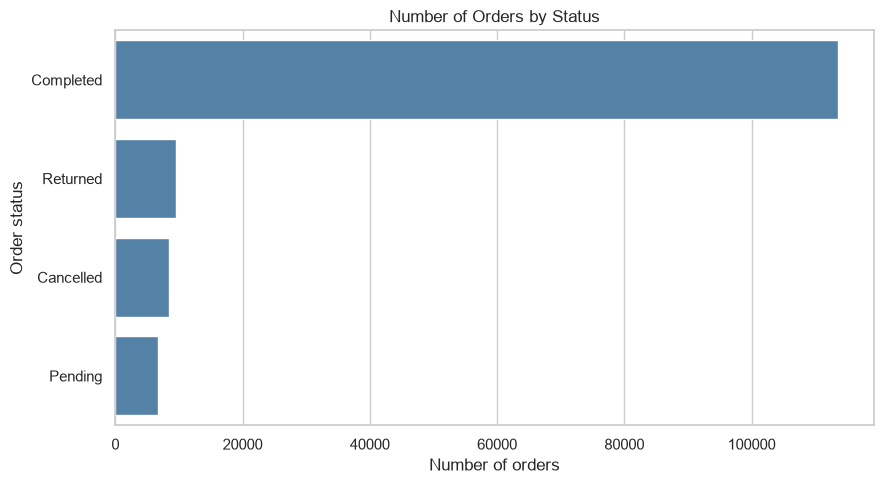

,orders
order_status,
Completed,113559
Returned,9462
Cancelled,8398
Pending,6697


In [11]:
plt.figure(figsize=(9, 5))
sns.countplot(data=sales_analysis, y="order_status",
              order=sales_analysis["order_status"].value_counts().index, color="steelblue")
plt.title("Number of Orders by Status")
plt.xlabel("Number of orders")
plt.ylabel("Order status")
plt.tight_layout()
plt.show()

display(sales_analysis["order_status"].value_counts(dropna=False).to_frame("orders"))

### 16.2 Sales channel

,currency,sales_channel,orders,revenue,profit,avg_profit
1,AED,Mobile App,1694,"2,156,660.26","843,670.40",498.03
3,AED,Website,1452,"1,726,882.16","690,858.99",475.80
0,AED,Marketplace,613,"762,700.61","298,777.11",487.40
2,AED,Social Media,413,"519,730.38","199,147.12",482.20
5,AUD,Mobile App,2752,"3,434,475.61","1,443,452.70",524.51
7,AUD,Website,2304,"3,119,075.64","1,314,687.32",570.61
4,AUD,Marketplace,1060,"1,396,611.49","577,435.81",544.75
6,AUD,Social Media,678,"863,527.77","356,819.32",526.28
9,CAD,Mobile App,2842,"3,777,652.25","1,652,714.94",581.53
11,CAD,Website,2447,"3,135,854.16","1,376,422.94",562.49


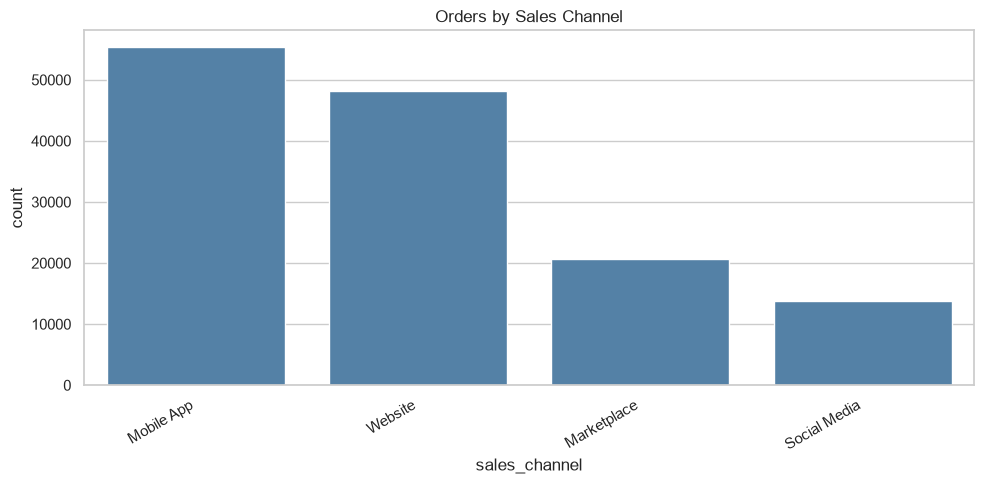

In [12]:
channel_summary = sales_analysis.groupby(["currency", "sales_channel"]).agg(
    orders=("order_id", "count"),
    revenue=("net_sales", "sum"),
    profit=("profit", "sum"),
    avg_profit=("profit", "mean")
).reset_index()
display(channel_summary.sort_values(["currency", "profit"], ascending=[True, False]))

plt.figure(figsize=(10, 5))
sns.countplot(data=sales_analysis, x="sales_channel",
              order=sales_analysis["sales_channel"].value_counts().index, color="steelblue")
plt.title("Orders by Sales Channel")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 16.3 Customer segment

In [13]:
segment_summary = sales_analysis.groupby(["currency", "customer_segment"]).agg(
    orders=("order_id", "count"),
    revenue=("net_sales", "sum"),
    profit=("profit", "sum"),
    average_profit=("profit", "mean"),
    average_rating=("customer_rating", "mean")
).reset_index()
display(segment_summary.sort_values(["currency", "profit"], ascending=[True, False]))

,currency,customer_segment,orders,revenue,profit,average_profit,average_rating
1,AED,Consumer,2237,"2,711,470.26","1,107,154.56",494.93,3.63
2,AED,Premium,1124,"1,390,251.07","518,125.67",460.97,3.74
0,AED,Business,387,"520,023.30","206,921.19",534.68,3.64
3,AED,VIP,424,"544,228.78","200,252.20",472.29,3.83
5,AUD,Consumer,3630,"4,727,030.25","2,034,569.97",560.49,3.63
6,AUD,Premium,1658,"2,147,384.35","854,924.76",515.64,3.72
4,AUD,Business,782,"1,024,265.30","437,618.56",559.61,3.64
7,AUD,VIP,724,"915,010.61","365,281.86",504.53,3.81
9,CAD,Consumer,3767,"4,949,787.77","2,217,561.69",588.68,3.62
10,CAD,Premium,1894,"2,457,382.21","1,043,378.67",550.89,3.73


### 16.4 Country and region

In [14]:
geo_summary = sales_analysis.groupby(["currency", "customer_country", "region"]).agg(
    orders=("order_id", "count"),
    revenue=("net_sales", "sum"),
    profit=("profit", "sum"),
    average_profit=("profit", "mean")
).reset_index()
display(geo_summary.sort_values(["currency", "profit"], ascending=[True, False]).head(30))

,currency,customer_country,region,orders,revenue,profit,average_profit
1,AED,UAE,South,2176,"2,712,378.44","1,049,637.83",482.37
0,AED,UAE,North,1996,"2,453,594.97","982,815.79",492.39
4,AUD,Australia,South,2883,"3,705,387.39","1,549,986.06",537.63
2,AUD,Australia,East,1457,"1,986,719.76","815,770.77",559.90
5,AUD,Australia,West,1412,"1,790,314.17","768,657.72",544.38
3,AUD,Australia,North,1042,"1,331,269.19","557,980.60",535.49
6,CAD,Canada,Central,2866,"3,804,113.87","1,674,004.76",584.09
7,CAD,Canada,East,2566,"3,318,205.11","1,457,322.61",567.94
8,CAD,Canada,West,1583,"2,076,529.50","903,711.19",570.89
11,EUR,Germany,South,4545,"6,341,834.40","2,990,721.24",658.02


### 16.5 Monthly sales and profit trends

The chart is separated by currency to avoid combining incomparable monetary values.

In [21]:
# Convert order_date into datetime format

sales_analysis["order_date"] = pd.to_datetime(
    sales_analysis["order_date"],
    errors="coerce"
)

# Check the data type
print(sales_analysis["order_date"].dtype)

datetime64[us]


In [22]:
# Monthly revenue analysis by currency

monthly = (
    sales_analysis
    .dropna(subset=["order_date"])
    .groupby([
        "currency",
        pd.Grouper(key="order_date", freq="MS")
    ])
    .agg(
        revenue=("net_sales", "sum")
    )
    .reset_index()
)

display(monthly)

,currency,order_date,revenue
0,AED,2021-01-01,"61,860.18"
1,AED,2021-02-01,"62,597.36"
2,AED,2021-03-01,"70,425.22"
3,AED,2021-04-01,"64,503.11"
4,AED,2021-05-01,"85,406.54"
...,...,...,...
415,USD,2025-08-01,"1,731,620.27"
416,USD,2025-09-01,"1,624,752.94"
417,USD,2025-10-01,"1,602,363.35"
418,USD,2025-11-01,"2,416,627.23"


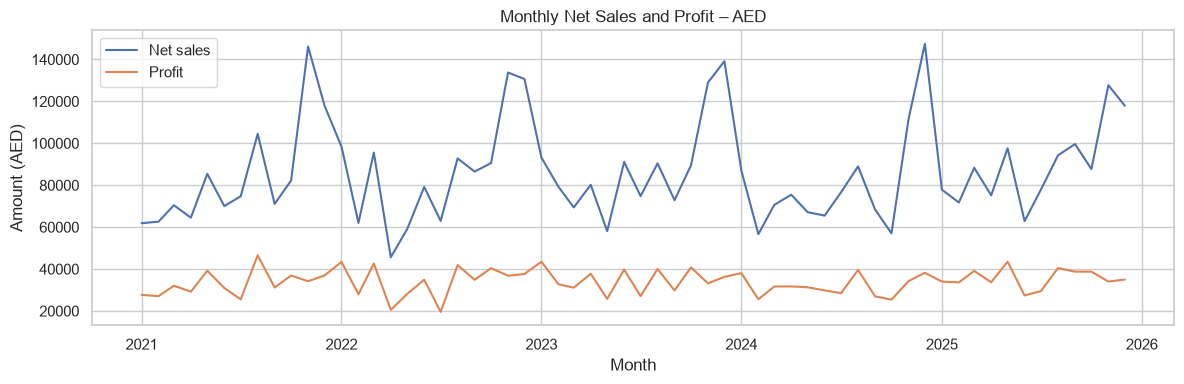

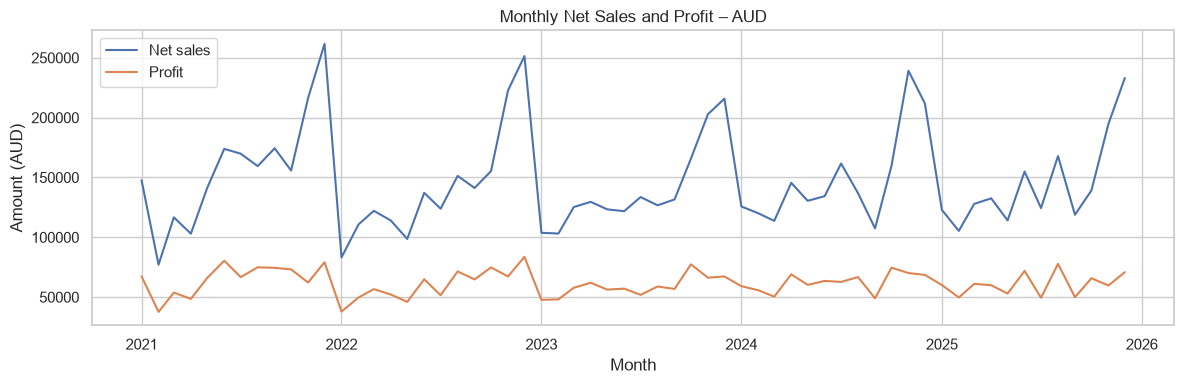

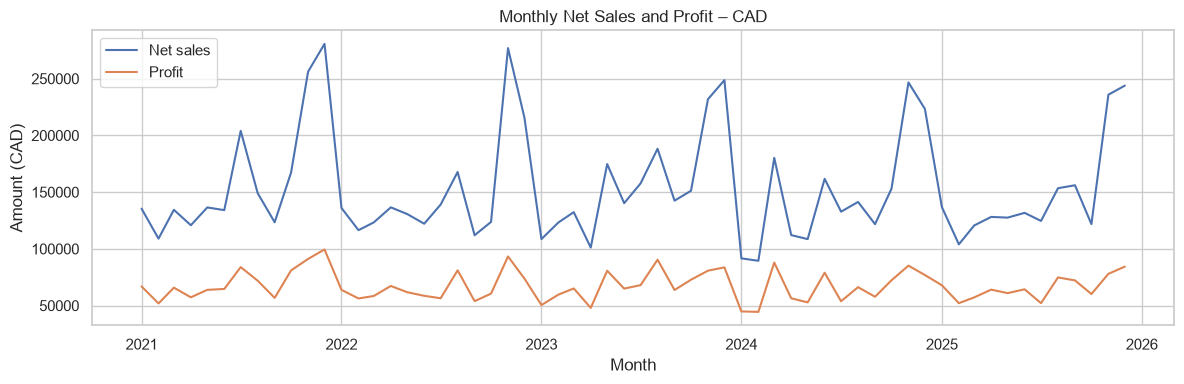

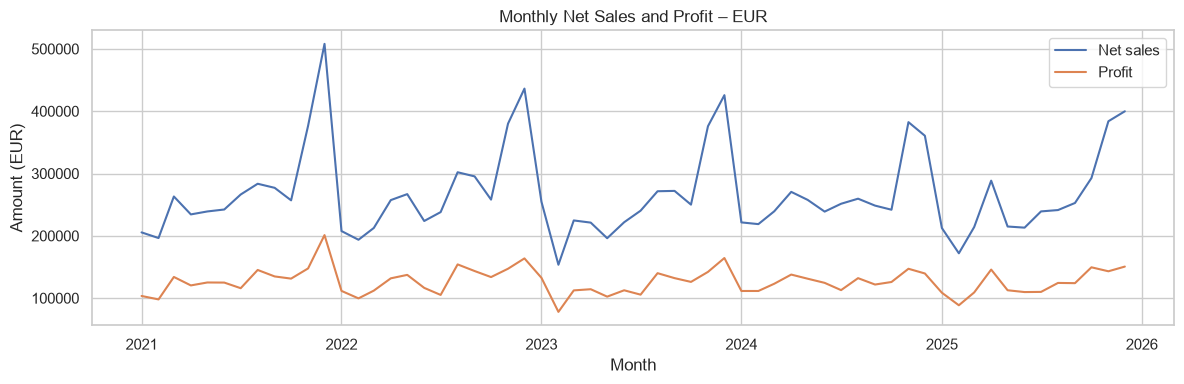

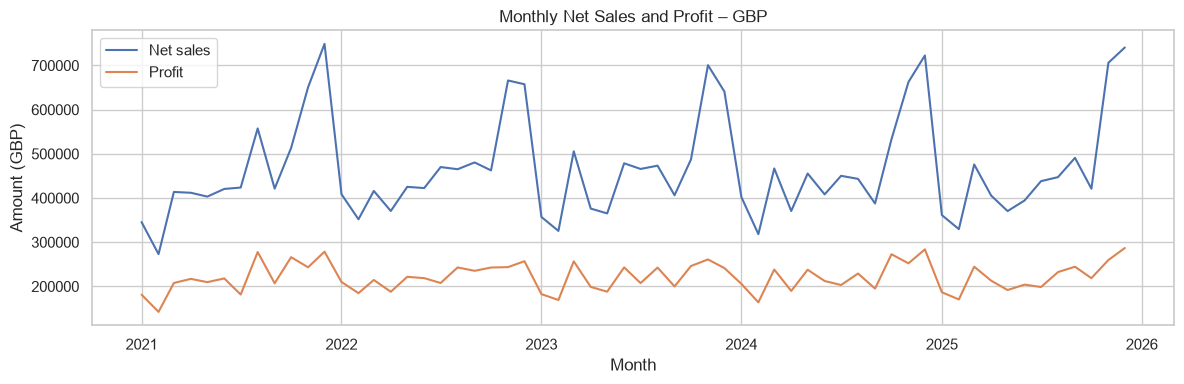

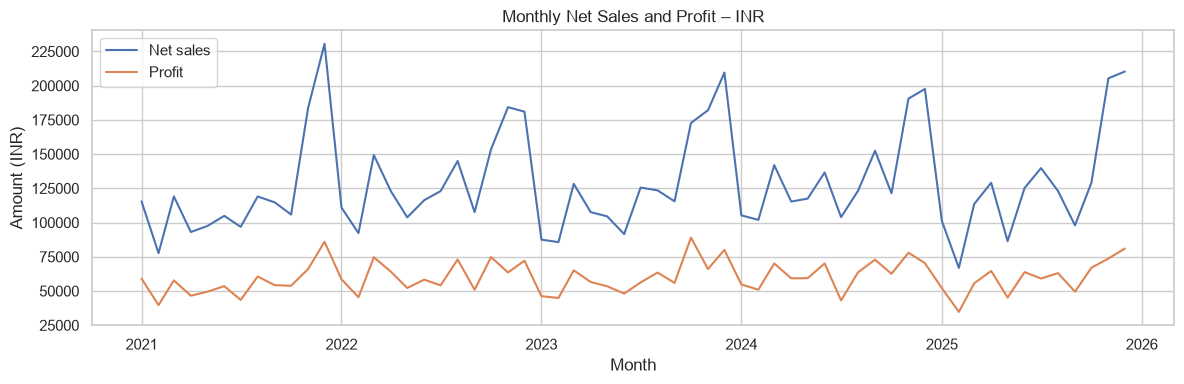

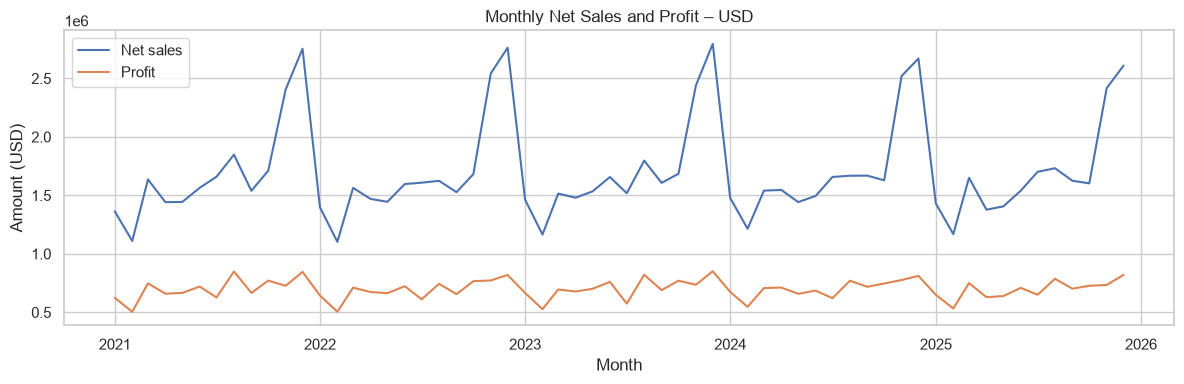

In [23]:
monthly = sales_analysis.dropna(subset=["order_date"]).groupby(
    ["currency", pd.Grouper(key="order_date", freq="MS")]
).agg(
    revenue=("net_sales", "sum"),
    profit=("profit", "sum"),
    orders=("order_id", "count")
).reset_index()

for curr in monthly["currency"].dropna().unique():
    part = monthly[monthly["currency"] == curr]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(part["order_date"], part["revenue"], label="Net sales")
    ax.plot(part["order_date"], part["profit"], label="Profit")
    ax.set_title(f"Monthly Net Sales and Profit – {curr}")
    ax.set_xlabel("Month")
    ax.set_ylabel(f"Amount ({curr})")
    ax.legend()
    plt.tight_layout()
    plt.show()

### 16.6 Product category and subcategory

Use the item-level table because product category is stored in the product catalog.

In [ ]:
# Category and subcategory financial values must be separated by currency.
category_summary = item_analysis.groupby(
    ["currency", "product_category"], dropna=False
).agg(
    item_rows=("product_id", "count"),
    quantity=("quantity", "sum"),
    gross_sales=("gross_sales", "sum"),
    profit=("profit", "sum"),
    average_line_profit=("profit", "mean")
).reset_index()
display(category_summary.sort_values(["currency", "profit"]))

subcategory_summary = item_analysis.groupby(
    ["currency", "product_category", "product_subcategory"], dropna=False
).agg(
    item_rows=("product_id", "count"),
    quantity=("quantity", "sum"),
    gross_sales=("gross_sales", "sum"),
    profit=("profit", "sum"),
    average_item_profit=("profit", "mean")
).reset_index().sort_values(["currency", "profit"])
print("Lowest-profit subcategories within each currency:")
for curr in subcategory_summary["currency"].dropna().unique():
    print(f"\nCurrency: {curr}")
    display(subcategory_summary[subcategory_summary["currency"] == curr].head(10))

,currency,product_category,item_rows,quantity,gross_sales,profit,average_line_profit
3,AED,Books & Media,913,1880,"82,627.16","39,209.16",42.95
6,AED,Grocery,782,1720,"94,190.35","47,264.79",60.44
2,AED,Beauty & Personal Care,836,1785,"149,234.44","69,420.22",83.04
14,AED,Toys & Games,775,1677,"177,664.80","76,191.59",98.31
12,AED,Pet Supplies,699,1515,"189,762.99","80,297.84",114.88
...,...,...,...,...,...,...,...
90,USD,Automotive,16488,34694,"10,577,223.87","3,569,933.57",216.52
103,USD,Sports & Outdoors,18206,38532,"10,005,193.45","3,980,408.71",218.63
99,USD,Home Appliances,15800,33712,"16,182,264.94","5,717,182.80",361.85
100,USD,Jewelry,13916,29312,"16,571,983.10","5,729,648.17",411.73


Lowest-profit subcategories within each currency:

Currency: AED


,currency,product_category,product_subcategory,item_rows,quantity,gross_sales,profit,average_item_profit
53,AED,Grocery,Pantry Staples,59,130,"5,097.34","2,216.30",37.56
22,AED,Beauty & Personal Care,Oral Care,51,118,"6,340.08","2,629.83",51.57
27,AED,Books & Media,Comics,85,175,"6,921.49","3,343.71",39.34
55,AED,Grocery,Snacks,43,95,"6,830.93","3,957.92",92.04
49,AED,Grocery,Dairy,51,114,"8,092.14","3,996.52",78.36
115,AED,Toys & Games,Dolls,51,101,"9,670.85","3,998.70",78.41
25,AED,Books & Media,Audiobooks,103,206,"9,001.08","4,177.34",40.56
52,AED,Grocery,Organic,66,152,"8,915.37","4,259.88",64.54
101,AED,Pet Supplies,Pet Beds,44,90,"12,970.23","4,527.35",102.89
30,AED,Books & Media,Music,115,250,"10,276.54","4,738.95",41.21



Currency: AUD


,currency,product_category,product_subcategory,item_rows,quantity,gross_sales,profit,average_item_profit
173,AUD,Grocery,Pantry Staples,94,207,"6,485.33","3,459.82",36.81
142,AUD,Beauty & Personal Care,Oral Care,79,173,"7,241.36","3,623.62",45.87
147,AUD,Books & Media,Comics,112,238,"10,372.99","5,473.27",48.87
169,AUD,Grocery,Dairy,76,152,"11,414.59","6,444.32",84.79
235,AUD,Toys & Games,Dolls,75,155,"15,103.63","6,956.54",92.75
144,AUD,Books & Media,Academic,134,288,"13,260.43","7,053.35",52.64
175,AUD,Grocery,Snacks,77,163,"12,448.17","7,213.42",93.68
150,AUD,Books & Media,Music,171,354,"15,201.18","7,784.01",45.52
145,AUD,Books & Media,Audiobooks,158,332,"15,084.46","7,887.90",49.92
149,AUD,Books & Media,Movies,156,339,"16,511.77","8,137.63",52.16



Currency: CAD


... (5 outputs left out)


Currency: INR


,currency,product_category,product_subcategory,item_rows,quantity,gross_sales,profit,average_item_profit
653,INR,Grocery,Pantry Staples,76,154,"5,688.15","3,198.52",42.09
622,INR,Beauty & Personal Care,Oral Care,76,173,"7,893.36","3,991.18",52.52
627,INR,Books & Media,Comics,94,204,"8,419.28","4,646.76",49.43
629,INR,Books & Media,Movies,116,247,"10,918.73","6,072.27",52.35
649,INR,Grocery,Dairy,78,138,"10,031.34","6,191.81",79.38
630,INR,Books & Media,Music,128,284,"12,314.36","7,170.43",56.02
655,INR,Grocery,Snacks,71,145,"11,456.95","7,296.51",102.77
715,INR,Toys & Games,Dolls,71,165,"14,507.54","7,519.14",105.90
626,INR,Books & Media,Children's Books,180,390,"13,942.37","7,685.78",42.70
652,INR,Grocery,Organic,86,199,"13,121.37","7,744.05",90.05



Currency: USD


,currency,product_category,product_subcategory,item_rows,quantity,gross_sales,profit,average_item_profit
773,USD,Grocery,Pantry Staples,1233,2521,"82,210.07","39,469.45",32.01
742,USD,Beauty & Personal Care,Oral Care,990,2109,"103,637.24","45,376.59",45.83
747,USD,Books & Media,Comics,1450,3156,"132,478.31","64,306.23",44.35
769,USD,Grocery,Dairy,985,2093,"153,500.60","79,206.41",80.41
775,USD,Grocery,Snacks,998,2056,"152,686.94","88,507.84",88.69
745,USD,Books & Media,Audiobooks,1789,3873,"175,423.68","90,095.99",50.36
750,USD,Books & Media,Music,2036,4291,"185,647.48","91,056.95",44.72
749,USD,Books & Media,Movies,1893,3986,"195,135.57","91,376.06",48.27
835,USD,Toys & Games,Dolls,1033,2251,"218,710.76","97,035.63",93.94
744,USD,Books & Media,Academic,2013,4247,"201,815.46","100,813.89",50.08


### 16.7 Most and least profitable products

In [ ]:
product_summary = item_analysis.groupby(
    ["currency", "product_id", "product_name", "product_category", "brand"],
    dropna=False
).agg(
    units_sold=("quantity", "sum"),
    item_rows=("order_id", "count"),
    gross_sales=("gross_sales", "sum"),
    profit=("profit", "sum"),
    average_profit_per_line=("profit", "mean")
).reset_index()

for curr in product_summary["currency"].dropna().unique():
    print(f"\n20 products with lowest total recorded profit – {curr}")
    display(product_summary[product_summary["currency"] == curr].nsmallest(20, "profit"))
    print(f"20 products with highest total recorded profit – {curr}")
    display(product_summary[product_summary["currency"] == curr].nlargest(20, "profit"))


20 products with lowest total recorded profit – AED


,currency,product_id,product_name,product_category,brand,units_sold,item_rows,gross_sales,profit,average_profit_per_line
46,AED,PROD-000047,HP Fundamental value-added paradigm Smart Watches,Electronics,HP,17,7,"11,436.24",-127.79,-18.26
1039,AED,PROD-001040,Mars Multi-tiered homogeneous artificial intel...,Grocery,Mars,5,3,31.55,18.87,6.29
1022,AED,PROD-001023,Mondelez Reduced mobile array Beverages,Grocery,Mondelez,17,8,109.48,34.79,4.35
1058,AED,PROD-001059,Coca-Cola Balanced impactful intranet Meat,Grocery,Coca-Cola,6,6,70.20,44.75,7.46
248,AED,PROD-000249,CoverGirl Open-source full-range moratorium Ha...,Beauty & Personal Care,CoverGirl,3,3,127.53,61.19,20.40
1029,AED,PROD-001030,Coca-Cola Object-based eco-centric ability Bev...,Grocery,Coca-Cola,25,10,161.50,65.86,6.59
282,AED,PROD-000283,Estée Lauder Visionary holistic concept Bath &...,Beauty & Personal Care,Estée Lauder,9,6,197.55,72.90,12.15
1141,AED,PROD-001142,Staples Re-contextualized dynamic standardizat...,Office Supplies,Staples,9,6,191.61,75.41,12.57
603,AED,PROD-000604,Nerf Extended homogeneous instruction set Remo...,Toys & Games,Nerf,9,5,298.80,76.70,15.34
1074,AED,PROD-001075,Kellogg's Operative incremental collaboration ...,Grocery,Kellogg's,14,7,181.16,83.24,11.89


20 products with highest total recorded profit – AED


,currency,product_id,product_name,product_category,brand,units_sold,item_rows,gross_sales,profit,average_profit_per_line
61,AED,PROD-000062,OnePlus Adaptive uniform success Gaming Consoles,Electronics,OnePlus,42,18,"56,302.68","14,964.18",831.34
3,AED,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Sony,33,13,"36,976.17","14,403.48","1,107.96"
993,AED,PROD-000994,Cartier Devolved mission-critical Graphic Inte...,Jewelry,Cartier,32,16,"31,095.68","12,745.43",796.59
76,AED,PROD-000077,OnePlus Switchable methodical neural-net TVs,Electronics,OnePlus,49,22,"66,623.34","12,569.34",571.33
136,AED,PROD-000137,Samsung Versatile asynchronous access Blenders,Home Appliances,Samsung,27,10,"19,811.79","10,453.66","1,045.37"
86,AED,PROD-000087,LG Reactive discrete parallelism Washing Machines,Home Appliances,LG,46,20,"22,955.84","10,043.99",502.20
963,AED,PROD-000964,Pandora Cross-platform incremental groupware N...,Jewelry,Pandora,26,12,"21,944.78","9,293.42",774.45
62,AED,PROD-000063,Xiaomi Fundamental motivating task-force Gamin...,Electronics,Xiaomi,36,15,"45,446.04","9,052.51",603.50
997,AED,PROD-000998,Tiffany Innovative optimal success Pendants,Jewelry,Tiffany,33,15,"26,730.00","9,037.49",602.50
978,AED,PROD-000979,Swarovski Innovative non-volatile portal Brace...,Jewelry,Swarovski,28,15,"20,267.80","8,869.19",591.28



20 products with lowest total recorded profit – AUD


,currency,product_id,product_name,product_category,brand,units_sold,item_rows,gross_sales,profit,average_profit_per_line
2197,AUD,PROD-001023,Mondelez Reduced mobile array Beverages,Grocery,Mondelez,22,12,141.68,44.61,3.72
2214,AUD,PROD-001040,Mars Multi-tiered homogeneous artificial intel...,Grocery,Mars,34,16,214.54,123.43,7.71
2204,AUD,PROD-001030,Coca-Cola Object-based eco-centric ability Bev...,Grocery,Coca-Cola,49,21,316.54,150.28,7.16
1974,AUD,PROD-000800,PetSafe Diverse 4thgeneration circuit Pet Food,Pet Supplies,PetSafe,24,16,386.64,169.25,10.58
1991,AUD,PROD-000817,Blue Buffalo Seamless executive solution Pet Toys,Pet Supplies,Blue Buffalo,15,8,357.60,173.88,21.73
2241,AUD,PROD-001067,PepsiCo Switchable multi-state definition Produce,Grocery,PepsiCo,24,9,353.76,181.23,20.14
2194,AUD,PROD-001020,Coca-Cola Distributed composite Graphic Interf...,Grocery,Coca-Cola,23,13,283.13,182.71,14.05
1647,AUD,PROD-000473,Random House Innovative scalable interface Fic...,Books & Media,Random House,24,11,306.00,190.27,17.30
1725,AUD,PROD-000551,Simon & Schuster Organized zero-defect hierarc...,Books & Media,Simon & Schuster,32,18,400.96,197.94,11.00
1982,AUD,PROD-000808,Iams Organic well-modulated archive Pet Food,Pet Supplies,Iams,34,16,530.40,198.20,12.39


... (18 outputs left out)


20 products with lowest total recorded profit – USD


,currency,product_id,product_name,product_category,brand,units_sold,item_rows,gross_sales,profit,average_profit_per_line
8072,USD,PROD-001023,Mondelez Reduced mobile array Beverages,Grocery,Mondelez,410,201,"2,640.40","1,033.97",5.14
8079,USD,PROD-001030,Coca-Cola Object-based eco-centric ability Bev...,Grocery,Coca-Cola,481,215,"3,107.26","1,535.30",7.14
8089,USD,PROD-001040,Mars Multi-tiered homogeneous artificial intel...,Grocery,Mars,433,215,"2,732.23","1,614.55",7.51
7918,USD,PROD-000869,Kong Expanded global portal Bird Cages,Pet Supplies,Kong,390,178,"3,911.70","1,769.17",9.94
7555,USD,PROD-000506,Pearson Public-key bottom-line knowledgebase C...,Books & Media,Pearson,396,187,"4,169.88","1,996.18",10.67
7330,USD,PROD-000281,Clinique Customizable non-volatile data-wareho...,Beauty & Personal Care,Clinique,422,198,"4,992.26","2,128.87",10.75
7521,USD,PROD-000472,Pearson Organic grid-enabled parallelism Fiction,Books & Media,Pearson,367,179,"5,138.00","2,469.65",13.80
7566,USD,PROD-000517,McGraw-Hill Automated exuding methodology Chil...,Books & Media,McGraw-Hill,439,208,"5,724.56","2,575.84",12.38
7857,USD,PROD-000808,Iams Organic well-modulated archive Pet Food,Pet Supplies,Iams,419,207,"6,536.40","2,692.14",13.01
7951,USD,PROD-000902,Graco Mandatory next generation hierarchy Toys,Baby & Kids,Graco,398,188,"8,230.64","2,703.74",14.38


20 products with highest total recorded profit – USD


,currency,product_id,product_name,product_category,brand,units_sold,item_rows,gross_sales,profit,average_profit_per_line
7100,USD,PROD-000051,HP Versatile actuating budgetary management Sm...,Electronics,HP,471,217,"650,333.25","222,534.75","1,025.51"
7111,USD,PROD-000062,OnePlus Adaptive uniform success Gaming Consoles,Electronics,OnePlus,481,213,"644,799.74","222,081.39","1,042.64"
8045,USD,PROD-000996,Messika Networked disintermediate knowledge us...,Jewelry,Messika,485,226,"469,809.80","218,976.86",968.92
7053,USD,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Sony,472,222,"528,871.28","186,652.21",840.78
7054,USD,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,OnePlus,411,188,"526,975.98","183,057.20",973.71
8052,USD,PROD-001003,Tous Diverse impactful software Chains,Jewelry,Tous,398,205,"362,490.44","177,228.68",864.53
8001,USD,PROD-000952,Mikimoto Monitored zero administration website...,Jewelry,Mikimoto,419,205,"386,456.27","173,218.95",844.97
7105,USD,PROD-000056,HP Function-based neutral access Cameras,Electronics,HP,405,184,"520,785.45","169,285.60",920.03
7123,USD,PROD-000074,Asus Configurable upward-trending matrix TVs,Electronics,Asus,495,231,"645,475.05","168,553.57",729.67
8017,USD,PROD-000968,Pandora Open-source solution-oriented leverage...,Jewelry,Pandora,416,196,"323,344.32","164,692.88",840.27


### 16.8 Negative-profit transactions and product lines

In [ ]:
negative_sales = sales_analysis[sales_analysis["profit"] < 0].copy()
negative_items = item_analysis[item_analysis["profit"] < 0].copy()

print("Negative-profit sales rows:", len(negative_sales))
print("Share of sales rows with negative profit:",
      len(negative_sales) / len(sales_analysis) * 100)
print("Negative-profit item rows:", len(negative_items))

print("Negative-profit order rate by currency:")
display(sales_analysis.groupby("currency").agg(
    orders=("order_id", "count"),
    negative_profit_orders=("profit", lambda s: (s < 0).sum()),
    negative_profit_rate_pct=("profit", lambda s: (s < 0).mean() * 100),
    total_profit=("profit", "sum")
).reset_index())

display(negative_sales[["order_id", "order_date", "currency", "sales_channel",
                        "customer_segment", "gross_sales", "discount_amount",
                        "shipping_cost", "product_cost", "profit"]].head(20))

Negative-profit sales rows: 1296
Share of sales rows with negative profit: 0.9383416838020214
Negative-profit item rows: 5426
Negative-profit order rate by currency:


,currency,orders,negative_profit_orders,negative_profit_rate_pct,total_profit
0,AED,4172,60,1.44,"2,032,453.62"
1,AUD,6794,76,1.12,"3,692,395.15"
2,CAD,7015,46,0.66,"4,035,038.56"
3,EUR,11593,61,0.53,"7,595,233.31"
4,GBP,20235,90,0.44,"13,266,357.16"
5,INR,5707,25,0.44,"3,601,652.06"
6,USD,82600,938,1.14,"41,923,265.90"


,order_id,order_date,currency,sales_channel,customer_segment,gross_sales,discount_amount,shipping_cost,product_cost,profit
1,ORD-773460,2025-12-24,EUR,Website,Premium,"3,144.64","1,456.06",9.00,"2,031.88",-22.47
149,ORD-567393,2021-12-14,USD,Mobile App,Premium,"5,558.21","2,943.84",29.48,"2,886.87",-89.50
156,ORD-613985,2022-11-09,GBP,Website,Premium,"3,350.18","1,683.01",11.09,"2,202.05",-201.44
158,ORD-324161,2021-11-30,USD,Social Media,Consumer,259.71,111.35,3.22,170.91,-12.16
163,ORD-828591,2021-11-30,EUR,Mobile App,VIP,"4,076.70","2,150.22",5.77,"2,533.00",-240.49
266,ORD-459603,2021-12-18,USD,Mobile App,VIP,665.22,399.13,11.96,331.44,-46.72
552,ORD-685844,2022-11-20,USD,Mobile App,Consumer,"1,646.60",675.84,21.54,"1,044.25",-5.54
773,ORD-590144,2023-11-10,GBP,Marketplace,Consumer,"1,751.91",768.89,20.00,"1,198.53",-18.91
1078,ORD-887807,2023-12-25,AED,Mobile App,Consumer,"3,307.56","1,502.36",36.28,"1,955.84",-60.38
1086,ORD-990629,2021-11-16,USD,Website,VIP,"2,294.60","1,267.92",3.38,"1,275.35",-176.80


## 17. Discount analysis

The item file contains `discount_percentage`. The sales file contains `discount_amount`. Start with the item-level discount percentage and compare it with item-level profit. Association is not proof that discounts caused the profit change.

,currency,n,pearson_r,pearson_p_value,spearman_r,spearman_p_value
0,USD,237779,-0.21,0.00,-0.22,0.00
1,EUR,33476,-0.18,0.00,-0.18,0.00
2,INR,16372,-0.17,0.00,-0.17,0.00
3,CAD,20389,-0.20,0.00,-0.20,0.00
4,GBP,58053,-0.18,0.00,-0.17,0.00
5,AUD,19488,-0.22,0.00,-0.22,0.00
6,AED,12012,-0.24,0.00,-0.24,0.00


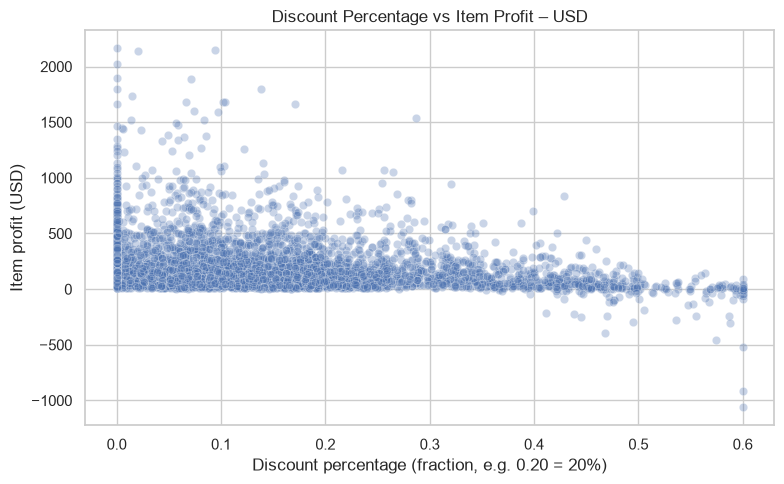

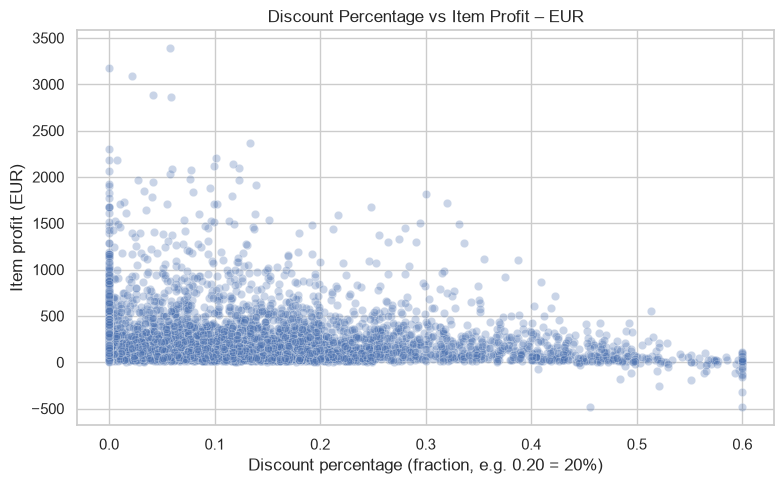

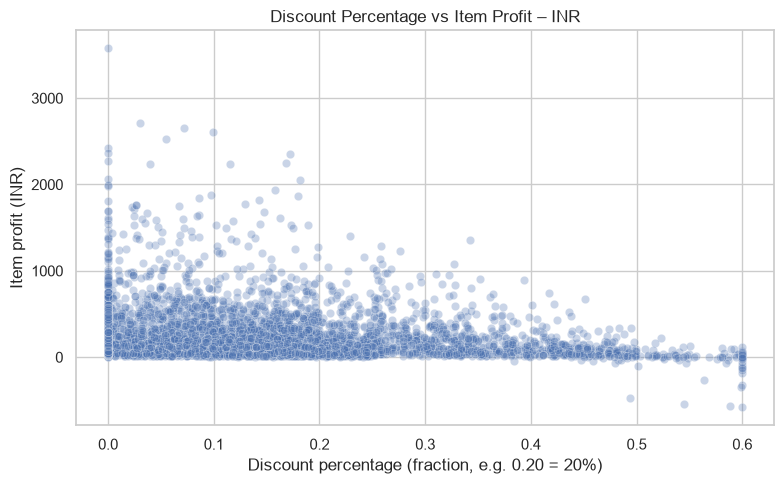

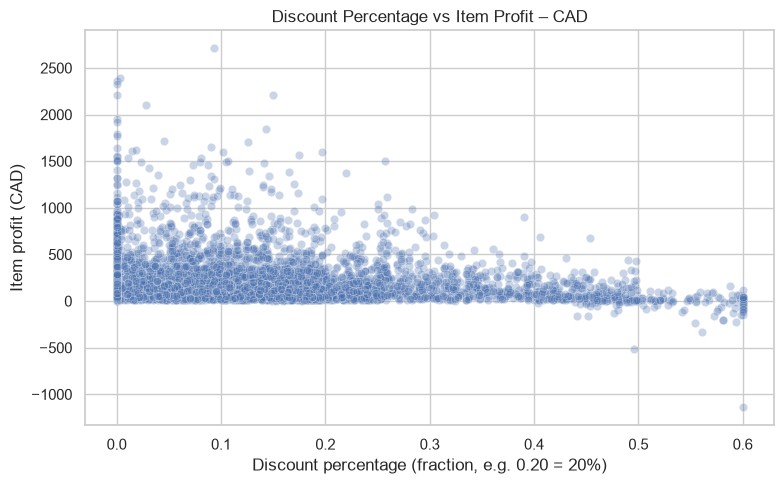

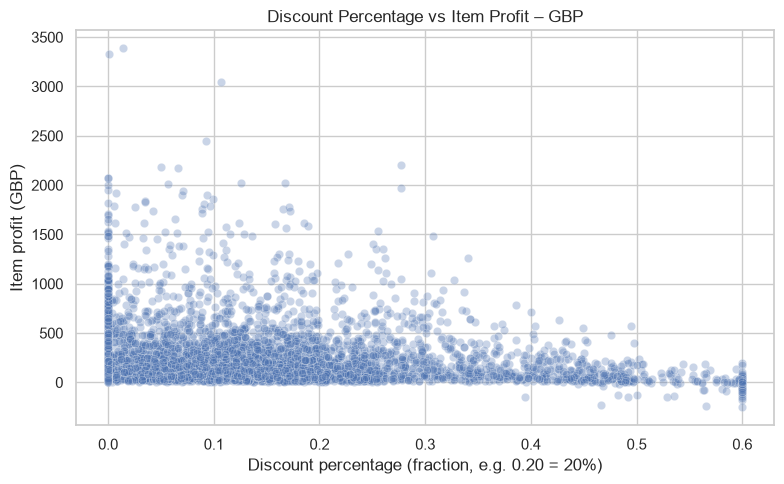

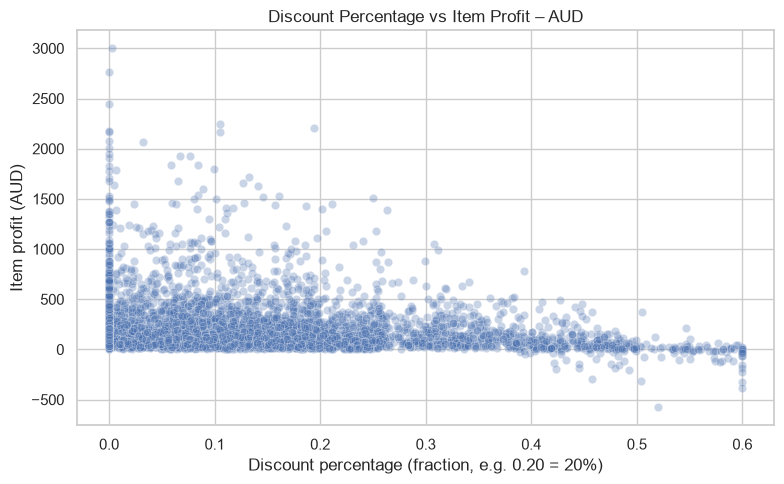

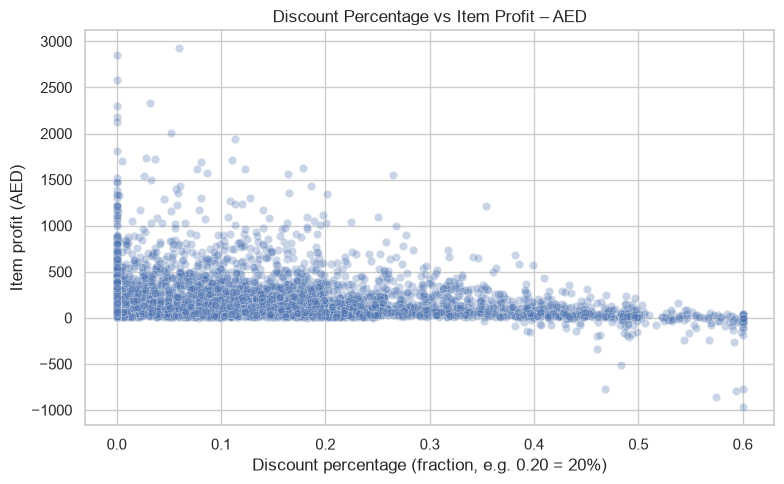

,currency,discount_band,item_rows,average_profit,median_profit
0,AED,0%,1432,251.01,148.68
1,AED,>0–10%,3612,227.38,134.79
2,AED,>10–20%,3921,176.49,105.90
3,AED,>20–30%,1534,162.86,98.24
4,AED,>30–50%,1274,102.87,68.01
5,AED,>50%,239,-69.93,-7.08
6,AUD,0%,2606,271.29,158.61
7,AUD,>0–10%,5587,245.79,143.42
8,AUD,>10–20%,6415,192.26,114.82
9,AUD,>20–30%,2426,179.77,110.38


In [ ]:
# Discount-profit analysis uses item-level data with currency mapped from order_id.
if "discount_percentage" in item_analysis.columns:
    discount_data = item_analysis[["currency", "discount_percentage", "profit", "gross_sales"]].dropna().copy()
    correlation_rows = []

    for curr in discount_data["currency"].dropna().unique():
        part = discount_data[discount_data["currency"] == curr]
        if len(part) >= 3 and part["discount_percentage"].nunique() > 1 and part["profit"].nunique() > 1:
            pearson_r, pearson_p = stats.pearsonr(part["discount_percentage"], part["profit"])
            spearman_r, spearman_p = stats.spearmanr(part["discount_percentage"], part["profit"])
            correlation_rows.append({
                "currency": curr, "n": len(part),
                "pearson_r": pearson_r, "pearson_p_value": pearson_p,
                "spearman_r": spearman_r, "spearman_p_value": spearman_p
            })

    discount_correlations = pd.DataFrame(correlation_rows)
    display(discount_correlations)

    # Visualise a sample per currency so amounts are not mixed across currencies.
    for curr in discount_data["currency"].dropna().unique():
        part = discount_data[discount_data["currency"] == curr]
        sample = part.sample(min(5000, len(part)), random_state=42)
        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=sample, x="discount_percentage", y="profit", alpha=0.3)
        plt.title(f"Discount Percentage vs Item Profit – {curr}")
        plt.xlabel("Discount percentage (fraction, e.g. 0.20 = 20%)")
        plt.ylabel(f"Item profit ({curr})")
        plt.tight_layout()
        plt.show()

    discount_data["discount_band"] = pd.cut(
        discount_data["discount_percentage"],
        bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0],
        labels=["0%", ">0–10%", ">10–20%", ">20–30%", ">30–50%", ">50%"]
    )
    discount_band_summary = discount_data.groupby(
        ["currency", "discount_band"], observed=False
    ).agg(
        item_rows=("profit", "size"),
        average_profit=("profit", "mean"),
        median_profit=("profit", "median")
    ).reset_index()
    display(discount_band_summary)
else:
    print("discount_percentage column is not available in item_analysis.")

## 18. Returns, cancellations and delivery performance

In [ ]:
for col in ["return_status", "order_status", "delivery_status", "return_reason"]:
    if col in sales_analysis.columns:
        print(f"\n{col}")
        display(sales_analysis[col].value_counts(dropna=False).to_frame("count"))

if "delivery_days" in sales_analysis.columns:
    display(sales_analysis.groupby("delivery_status").agg(
        orders=("order_id", "count"),
        average_delivery_days=("delivery_days", "mean"),
        average_profit=("profit", "mean")
    ))

if "return_status" in sales_analysis.columns:
    display(sales_analysis.groupby("return_status", dropna=False).agg(
        orders=("order_id", "count"),
        average_profit=("profit", "mean"),
        total_profit=("profit", "sum")
    ))


return_status


,count
return_status,
NaN,128654
Returned,9462



order_status


,count
order_status,
Completed,113559
Returned,9462
Cancelled,8398
Pending,6697



delivery_status


,count
delivery_status,
On Time,86916
Cancelled,24557
Delayed,16886
Early,9757



return_reason


,count
return_reason,
NaN,128654
Wrong Product,1237
Other,1208
Changed Mind,1204
Size Issue,1182
Defective Product,1174
Late Delivery,1172
Product Not as Expected,1147
Damaged Product,1138


,orders,average_delivery_days,average_profit
delivery_status,,,
Cancelled,24557,NaN,667.34
Delayed,16886,6.83,525.67
Early,9757,2.93,532.35
On Time,86916,4.30,525.66


,orders,average_profit,total_profit
return_status,,,
Returned,9462,731.94,"6,925,597.40"
NaN,128654,538.04,"69,220,798.36"


## 19. Customer analysis

In [ ]:
# Customer financial metrics are grouped by currency.
customer_summary = sales_analysis.groupby(
    ["currency", "customer_id", "customer_segment", "customer_type"], dropna=False
).agg(
    order_count=("order_id", "nunique"),
    total_revenue=("net_sales", "sum"),
    total_profit=("profit", "sum"),
    average_order_profit=("profit", "mean"),
    average_rating=("customer_rating", "mean")
).reset_index()

print("Customer-currency summary rows:", len(customer_summary))
for curr in customer_summary["currency"].dropna().unique():
    print(f"\nLowest-profit customers – {curr}")
    display(customer_summary[customer_summary["currency"] == curr].nsmallest(10, "total_profit"))
    print(f"Highest-profit customers – {curr}")
    display(customer_summary[customer_summary["currency"] == curr].nlargest(10, "total_profit"))

Customer-currency summary rows: 24911

Lowest-profit customers – AED


,currency,customer_id,customer_segment,customer_type,order_count,total_revenue,total_profit,average_order_profit,average_rating
233,AED,CUST-007528,VIP,New,1,171.25,44.04,44.04,4.10
635,AED,CUST-020810,Premium,New,1,185.89,80.87,80.87,2.40
250,AED,CUST-008069,VIP,Loyal,4,"4,201.53",121.09,30.27,3.92
594,AED,CUST-019347,Premium,Returning,3,"2,190.46",139.49,46.50,3.57
11,AED,CUST-000392,Consumer,Returning,2,411.02,208.56,104.28,3.75
115,AED,CUST-003683,Consumer,Returning,3,416.14,212.57,70.86,3.87
90,AED,CUST-003049,Consumer,Returning,1,540.73,225.33,225.33,3.20
129,AED,CUST-004057,Premium,Loyal,7,"7,202.20",238.87,34.12,3.90
748,AED,CUST-024279,Consumer,Returning,2,508.29,242.38,121.19,3.90
550,AED,CUST-017967,Premium,New,1,556.09,260.27,260.27,4.40


Highest-profit customers – AED


,currency,customer_id,customer_segment,customer_type,order_count,total_revenue,total_profit,average_order_profit,average_rating
617,AED,CUST-020297,Consumer,Loyal,11,"21,858.48","8,600.57",781.87,3.38
273,AED,CUST-008799,Consumer,Loyal,13,"24,444.72","7,978.19",613.71,3.74
438,AED,CUST-014236,Premium,Loyal,10,"17,198.63","7,914.03",791.40,3.53
496,AED,CUST-016052,Consumer,Loyal,7,"19,272.42","7,861.42","1,123.06",3.95
427,AED,CUST-013898,Consumer,Loyal,12,"19,511.69","7,816.26",651.36,3.61
60,AED,CUST-002194,Consumer,Loyal,7,"16,717.24","7,335.25","1,047.89",3.28
101,AED,CUST-003265,Premium,Loyal,9,"16,452.57","7,111.41",790.16,3.49
576,AED,CUST-018765,Premium,Loyal,8,"15,876.52","6,956.54",869.57,3.94
480,AED,CUST-015803,Consumer,Loyal,7,"15,743.08","6,948.74",992.68,3.67
625,AED,CUST-020504,Premium,Loyal,10,"17,256.51","6,891.84",689.18,3.50



Lowest-profit customers – AUD


,currency,customer_id,customer_segment,customer_type,order_count,total_revenue,total_profit,average_order_profit,average_rating
1417,AUD,CUST-013119,VIP,Returning,3,"2,606.37",-25.67,-8.56,3.60
1516,AUD,CUST-015121,Consumer,New,1,91.64,38.05,38.05,3.10
1902,AUD,CUST-022966,Premium,Returning,3,748.95,61.29,20.43,3.83
1011,AUD,CUST-004926,Business,Returning,2,"1,617.65",62.17,31.08,3.35
1590,AUD,CUST-016683,VIP,New,1,166.99,94.59,94.59,4.10
800,AUD,CUST-000567,Consumer,New,1,219.96,125.41,125.41,3.60
1697,AUD,CUST-019016,VIP,Returning,1,288.17,127.76,127.76,NaN
1112,AUD,CUST-006976,Premium,Loyal,4,"7,716.77",147.22,36.81,3.97
837,AUD,CUST-001272,Premium,Loyal,5,"5,534.52",156.15,31.23,3.86
1768,AUD,CUST-020356,VIP,Loyal,2,408.23,159.23,79.62,4.50


... (18 outputs left out)


Lowest-profit customers – USD


,currency,customer_id,customer_segment,customer_type,order_count,total_revenue,total_profit,average_order_profit,average_rating
17745,USD,CUST-012880,Consumer,Returning,2,"7,573.12","-1,117.39",-558.70,4.10
12508,USD,CUST-004099,VIP,Returning,2,"2,524.25",-575.07,-287.53,4.20
11810,USD,CUST-002934,VIP,Returning,2,"4,171.68",-430.80,-215.40,3.70
24745,USD,CUST-024731,Premium,Returning,2,"2,595.34",-377.88,-188.94,3.50
23322,USD,CUST-022333,Premium,New,1,"2,693.56",-240.90,-240.90,3.80
19163,USD,CUST-015325,Premium,Returning,3,"3,353.41",-204.96,-68.32,3.65
10902,USD,CUST-001443,Premium,Loyal,5,"4,300.71",-193.85,-38.77,3.27
20974,USD,CUST-018359,Premium,Loyal,6,"2,457.99",-142.82,-23.80,3.62
19946,USD,CUST-016642,VIP,Loyal,3,"4,447.52",-127.06,-42.35,4.10
19481,USD,CUST-015874,Premium,Returning,2,"1,811.58",-90.18,-45.09,3.55


Highest-profit customers – USD


,currency,customer_id,customer_segment,customer_type,order_count,total_revenue,total_profit,average_order_profit,average_rating
20674,USD,CUST-017828,Business,Loyal,14,"28,092.99","12,397.89",885.56,3.63
17352,USD,CUST-012262,Consumer,Loyal,12,"24,292.99","11,766.56",980.55,3.46
20917,USD,CUST-018253,Consumer,Loyal,11,"24,067.76","11,543.45","1,049.40",3.96
15342,USD,CUST-008822,Premium,Loyal,10,"25,803.66","11,059.20","1,105.92",3.88
10669,USD,CUST-001048,Consumer,Loyal,14,"25,445.56","10,943.34",781.67,3.69
13912,USD,CUST-006451,Consumer,Loyal,14,"25,236.20","10,838.98",774.21,3.56
16998,USD,CUST-011608,Consumer,Loyal,10,"23,522.98","10,824.07","1,082.41",3.19
10849,USD,CUST-001351,Premium,Loyal,9,"23,883.47","10,730.26","1,192.25",4.07
20321,USD,CUST-017251,Premium,Loyal,15,"29,375.34","10,563.05",704.20,3.54
12822,USD,CUST-004632,Consumer,Loyal,10,"25,241.51","10,149.04","1,014.90",3.44


## 20. Marketing channel analysis

In [ ]:
marketing_summary = sales_analysis.groupby(
    ["currency", "marketing_channel"], dropna=False
).agg(
    orders=("order_id", "count"),
    revenue=("net_sales", "sum"),
    profit=("profit", "sum"),
    average_profit=("profit", "mean"),
    average_rating=("customer_rating", "mean")
).reset_index()
display(marketing_summary.sort_values(["currency", "profit"], ascending=[True, False]))

,currency,marketing_channel,orders,revenue,profit,average_profit,average_rating
6,AED,Organic Search,913,"1,166,079.51","459,327.49",503.10,3.70
4,AED,Google Ads,632,"776,924.47","302,103.74",478.01,3.70
1,AED,Direct,615,"723,148.24","298,156.18",484.81,3.67
3,AED,Facebook Ads,442,"526,631.39","201,592.96",456.09,3.68
5,AED,Instagram,409,"520,241.90","200,457.90",490.12,3.66
2,AED,Email Marketing,376,"476,946.46","182,585.34",485.60,3.66
7,AED,Referral,317,"385,897.09","154,195.25",486.42,3.65
0,AED,Affiliate,188,"234,079.00","94,561.34",502.99,3.69
8,AED,TikTok,156,"201,930.06","75,244.41",482.34,3.71
9,AED,YouTube,124,"154,095.29","64,229.01",517.98,3.72


## 21. Correlation analysis

Correlation is meaningful only for numeric variables and does not establish causation. Inspect the variables and currency context before interpreting monetary correlations.


Correlation matrix – USD


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,-0.00,0.00,-0.01,-0.00,-0.01,-0.01,-0.00,-0.00
quantity,-0.00,1.00,0.64,0.54,0.59,0.51,0.60,0.58,0.51,-0.22,0.16,0.01,0.01,0.06,0.53,0.42
gross_sales,-0.00,0.64,1.00,0.73,0.97,0.33,0.97,0.99,0.78,-0.34,0.26,0.01,0.00,0.04,0.83,0.65
discount_amount,-0.00,0.54,0.73,1.00,0.54,0.17,0.54,0.71,0.18,-0.61,0.14,0.01,0.01,0.04,0.61,0.48
tax_amount,-0.00,0.59,0.97,0.54,1.00,0.35,1.00,0.96,0.90,-0.19,0.27,0.00,0.00,0.04,0.80,0.63
shipping_cost,0.00,0.51,0.33,0.17,0.35,1.00,0.36,0.30,0.36,-0.04,0.10,-0.31,-0.34,0.01,0.30,0.23
net_sales,-0.00,0.60,0.97,0.54,1.00,0.36,1.00,0.96,0.90,-0.19,0.27,-0.00,-0.00,0.04,0.80,0.63
product_cost,-0.00,0.58,0.99,0.71,0.96,0.30,0.96,1.00,0.73,-0.39,0.25,0.00,0.00,0.04,0.82,0.64
profit,-0.00,0.51,0.78,0.18,0.90,0.36,0.90,0.73,1.00,0.15,0.24,0.00,0.00,0.03,0.64,0.50
profit_margin_percentage,0.00,-0.22,-0.34,-0.61,-0.19,-0.04,-0.19,-0.39,0.15,1.00,-0.05,0.04,0.04,-0.04,-0.27,-0.21


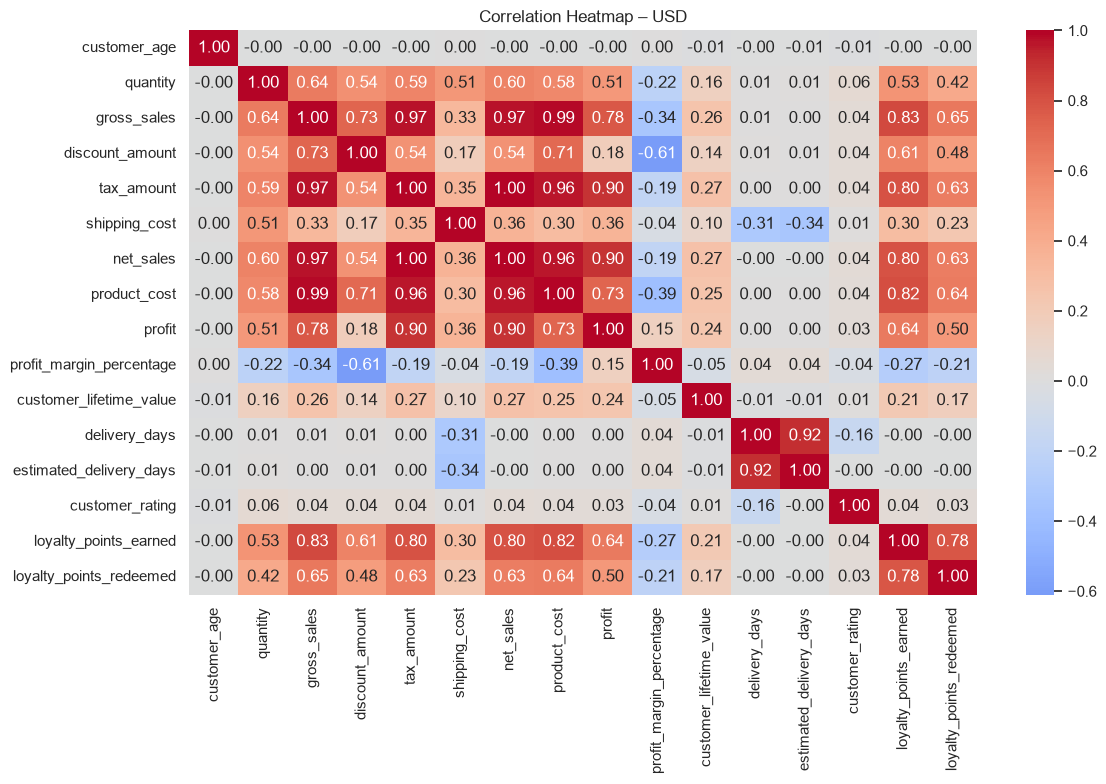


Correlation matrix – EUR


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,-0.01,0.00,0.00,0.00,-0.00,0.00,0.00,0.01,0.01,0.01,0.01,0.01,0.00,0.01,0.01
quantity,-0.01,1.00,0.64,0.54,0.59,0.50,0.59,0.58,0.54,-0.21,0.17,-0.01,-0.00,0.06,0.52,0.40
gross_sales,0.00,0.64,1.00,0.72,0.97,0.33,0.97,0.98,0.84,-0.32,0.27,-0.01,-0.00,0.05,0.83,0.65
discount_amount,0.00,0.54,0.72,1.00,0.53,0.17,0.53,0.70,0.26,-0.60,0.15,-0.01,-0.01,0.06,0.61,0.46
tax_amount,0.00,0.59,0.97,0.53,1.00,0.34,1.00,0.96,0.94,-0.18,0.28,-0.00,-0.00,0.04,0.81,0.63
shipping_cost,-0.00,0.50,0.33,0.17,0.34,1.00,0.35,0.30,0.35,-0.04,0.09,-0.30,-0.33,0.00,0.30,0.23
net_sales,0.00,0.59,0.97,0.53,1.00,0.35,1.00,0.96,0.94,-0.18,0.28,-0.01,-0.01,0.04,0.81,0.63
product_cost,0.00,0.58,0.98,0.70,0.96,0.30,0.96,1.00,0.79,-0.39,0.27,-0.01,-0.00,0.04,0.82,0.64
profit,0.01,0.54,0.84,0.26,0.94,0.35,0.94,0.79,1.00,0.08,0.26,-0.00,-0.00,0.02,0.69,0.54
profit_margin_percentage,0.01,-0.21,-0.32,-0.60,-0.18,-0.04,-0.18,-0.39,0.08,1.00,-0.05,0.04,0.04,-0.07,-0.26,-0.20


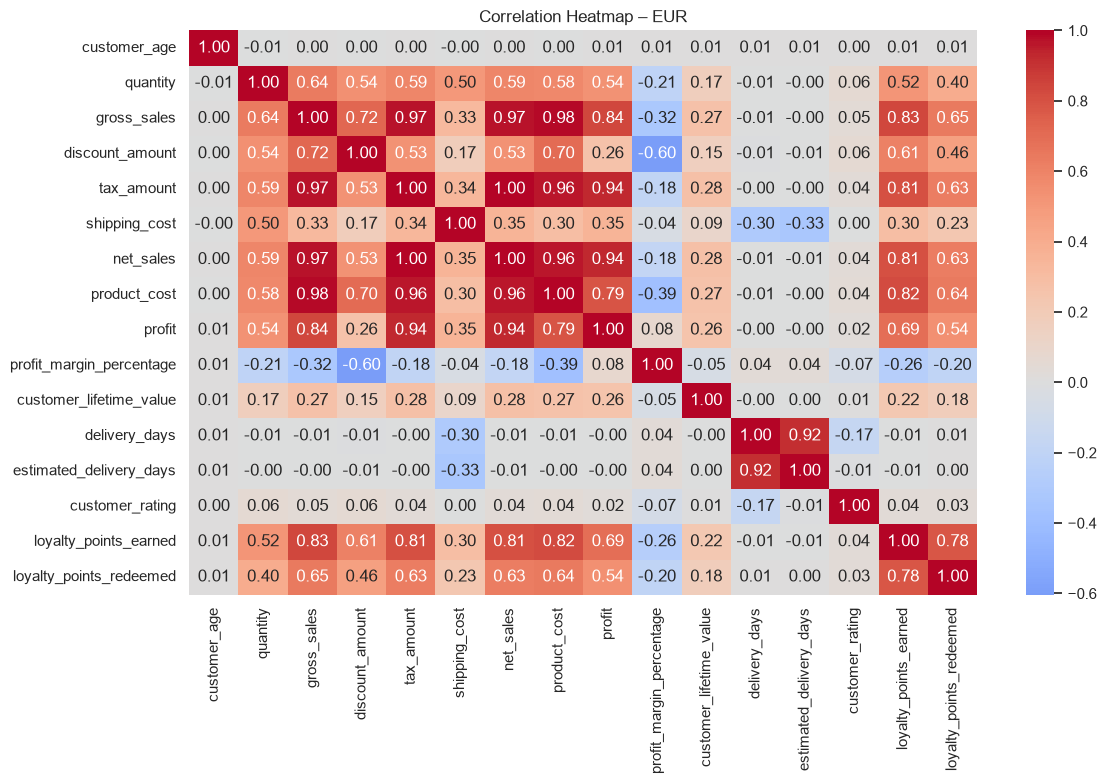


Correlation matrix – INR


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,0.02,0.02,0.01,0.01,0.00,0.01,0.01,0.01,-0.01,0.06,0.01,0.00,0.01,0.02,0.01
quantity,0.02,1.00,0.64,0.55,0.60,0.48,0.60,0.58,0.54,-0.23,0.13,0.01,-0.01,0.04,0.53,0.43
gross_sales,0.02,0.64,1.00,0.74,0.97,0.32,0.97,0.98,0.83,-0.35,0.23,-0.01,-0.01,0.02,0.84,0.65
discount_amount,0.01,0.55,0.74,1.00,0.55,0.15,0.55,0.72,0.26,-0.61,0.14,-0.00,-0.00,0.02,0.64,0.51
tax_amount,0.01,0.60,0.97,0.55,1.00,0.34,1.00,0.96,0.93,-0.22,0.24,-0.01,-0.02,0.02,0.80,0.62
shipping_cost,0.00,0.48,0.32,0.15,0.34,1.00,0.35,0.29,0.36,-0.02,0.07,-0.30,-0.33,0.02,0.28,0.23
net_sales,0.01,0.60,0.97,0.55,1.00,0.35,1.00,0.96,0.93,-0.21,0.24,-0.01,-0.02,0.02,0.80,0.62
product_cost,0.01,0.58,0.98,0.72,0.96,0.29,0.96,1.00,0.78,-0.41,0.23,-0.01,-0.01,0.02,0.82,0.63
profit,0.01,0.54,0.83,0.26,0.93,0.36,0.93,0.78,1.00,0.06,0.22,-0.02,-0.02,0.03,0.68,0.53
profit_margin_percentage,-0.01,-0.23,-0.35,-0.61,-0.22,-0.02,-0.21,-0.41,0.06,1.00,-0.09,0.02,0.03,-0.02,-0.29,-0.23


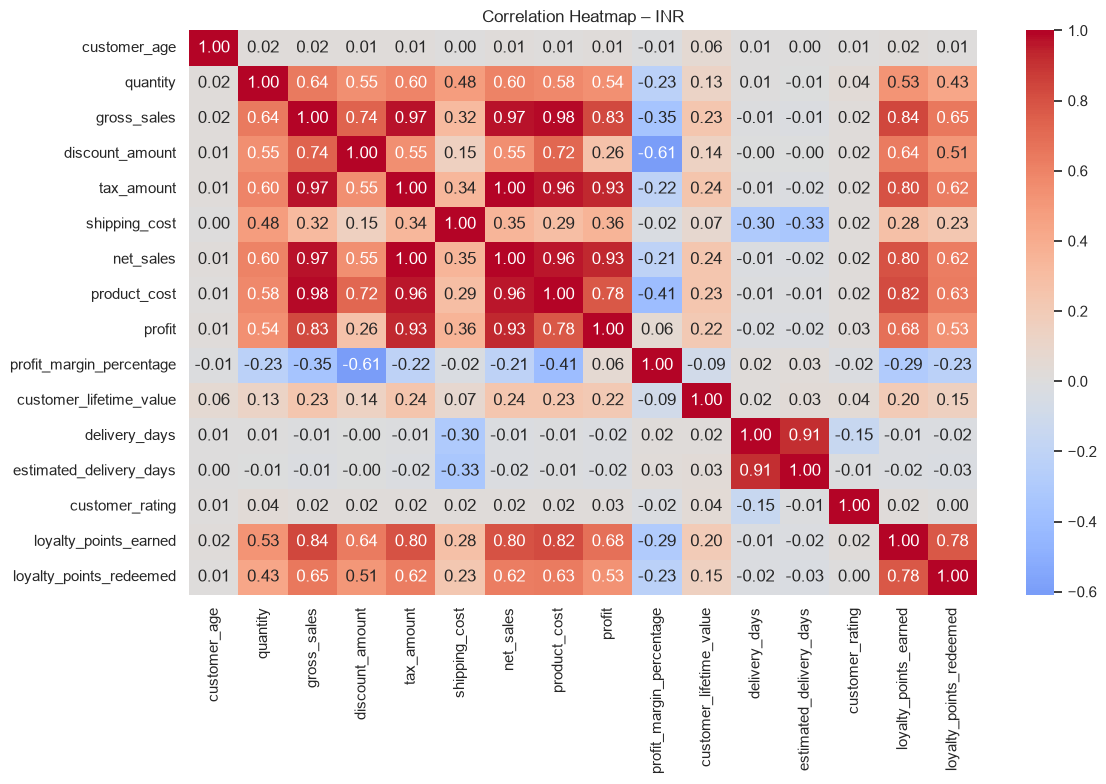


Correlation matrix – CAD


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,-0.00,-0.00,-0.01,0.00,0.01,0.00,-0.00,0.01,0.01,-0.01,0.01,-0.00,0.01,-0.00,0.01
quantity,-0.00,1.00,0.65,0.55,0.60,0.53,0.60,0.59,0.52,-0.22,0.16,0.00,0.00,0.04,0.52,0.41
gross_sales,-0.00,0.65,1.00,0.73,0.97,0.34,0.97,0.98,0.81,-0.32,0.25,0.01,0.01,0.03,0.81,0.65
discount_amount,-0.01,0.55,0.73,1.00,0.54,0.19,0.54,0.71,0.22,-0.61,0.15,-0.00,-0.00,0.02,0.62,0.48
tax_amount,0.00,0.60,0.97,0.54,1.00,0.36,1.00,0.96,0.92,-0.18,0.26,0.01,0.01,0.02,0.78,0.63
shipping_cost,0.01,0.53,0.34,0.19,0.36,1.00,0.37,0.31,0.36,-0.06,0.09,-0.31,-0.35,0.00,0.29,0.23
net_sales,0.00,0.60,0.97,0.54,1.00,0.37,1.00,0.96,0.92,-0.18,0.26,0.01,0.01,0.02,0.78,0.63
product_cost,-0.00,0.59,0.98,0.71,0.96,0.31,0.96,1.00,0.76,-0.38,0.25,0.01,0.01,0.02,0.80,0.64
profit,0.01,0.52,0.81,0.22,0.92,0.36,0.92,0.76,1.00,0.13,0.23,0.01,0.01,0.02,0.64,0.52
profit_margin_percentage,0.01,-0.22,-0.32,-0.61,-0.18,-0.06,-0.18,-0.38,0.13,1.00,-0.05,0.05,0.06,-0.03,-0.27,-0.20


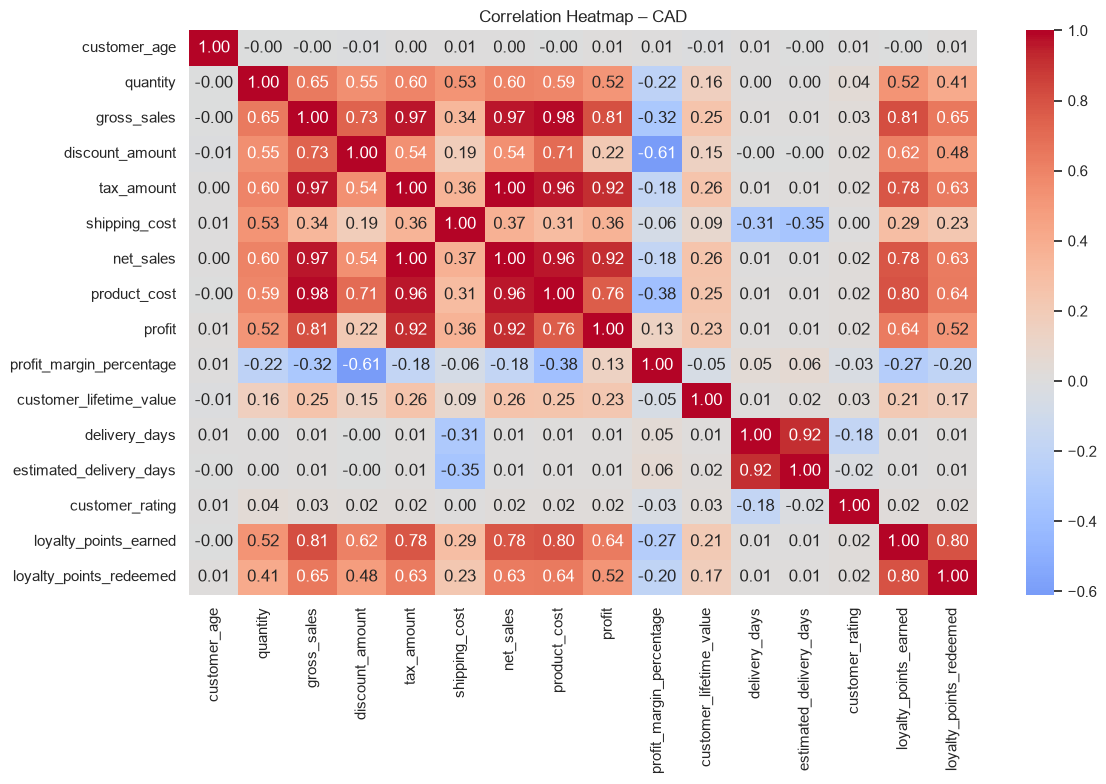


Correlation matrix – GBP


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.01,-0.01,-0.01,-0.01,-0.00,0.00,0.01
quantity,-0.00,1.00,0.64,0.53,0.59,0.49,0.59,0.58,0.53,-0.22,0.15,-0.00,0.00,0.07,0.52,0.41
gross_sales,0.00,0.64,1.00,0.72,0.97,0.31,0.97,0.98,0.83,-0.34,0.25,-0.00,0.00,0.05,0.82,0.65
discount_amount,0.00,0.53,0.72,1.00,0.52,0.15,0.52,0.70,0.24,-0.62,0.13,-0.00,0.00,0.05,0.59,0.46
tax_amount,0.00,0.59,0.97,0.52,1.00,0.32,1.00,0.96,0.93,-0.19,0.26,-0.00,0.00,0.05,0.80,0.63
shipping_cost,0.00,0.49,0.31,0.15,0.32,1.00,0.33,0.28,0.34,-0.03,0.09,-0.31,-0.33,0.00,0.28,0.23
net_sales,0.00,0.59,0.97,0.52,1.00,0.33,1.00,0.96,0.93,-0.19,0.26,-0.00,-0.00,0.05,0.80,0.63
product_cost,0.00,0.58,0.98,0.70,0.96,0.28,0.96,1.00,0.79,-0.40,0.25,-0.00,0.00,0.05,0.81,0.64
profit,0.00,0.53,0.83,0.24,0.93,0.34,0.93,0.79,1.00,0.08,0.25,0.00,0.00,0.04,0.69,0.54
profit_margin_percentage,-0.01,-0.22,-0.34,-0.62,-0.19,-0.03,-0.19,-0.40,0.08,1.00,-0.05,0.04,0.04,-0.04,-0.27,-0.21


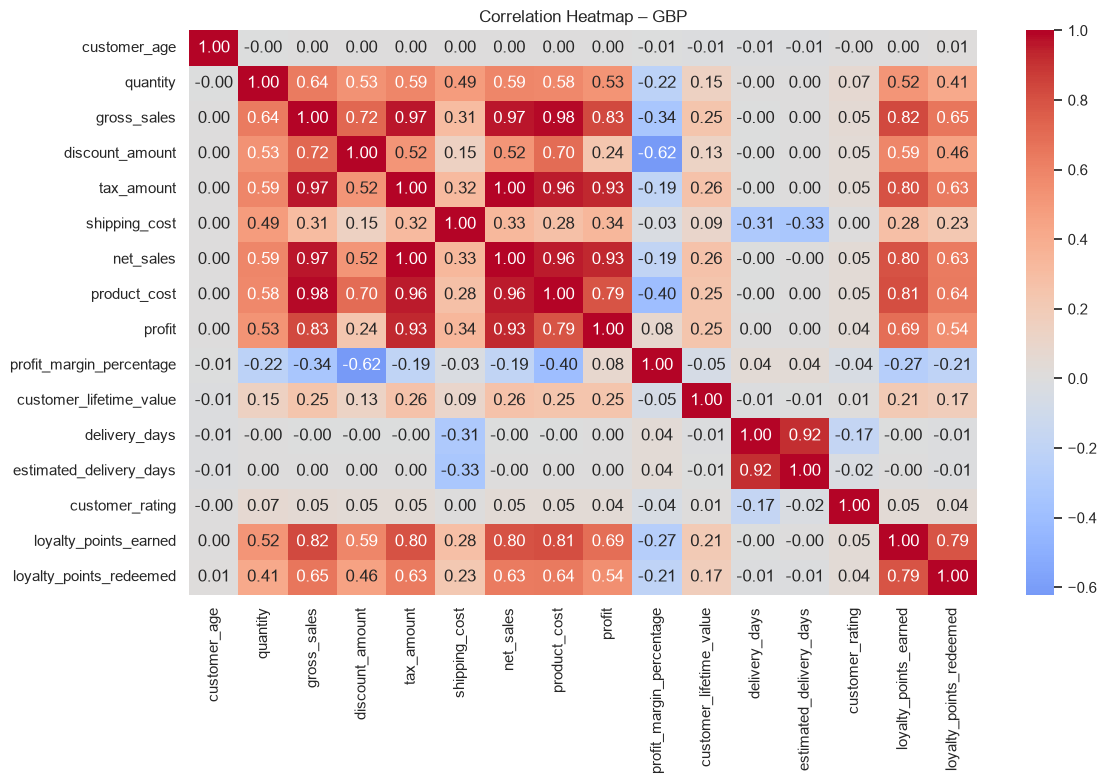


Correlation matrix – AUD


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,0.00,-0.01,0.00,-0.01,-0.02,-0.01,-0.01,-0.01,0.01,0.03,-0.01,-0.00,0.00,-0.01,-0.01
quantity,0.00,1.00,0.64,0.52,0.59,0.53,0.60,0.58,0.51,-0.20,0.17,-0.00,-0.01,0.05,0.53,0.42
gross_sales,-0.01,0.64,1.00,0.72,0.97,0.34,0.97,0.99,0.77,-0.32,0.27,-0.02,-0.03,0.04,0.81,0.66
discount_amount,0.00,0.52,0.72,1.00,0.52,0.18,0.52,0.71,0.16,-0.62,0.13,0.00,-0.01,0.04,0.58,0.49
tax_amount,-0.01,0.59,0.97,0.52,1.00,0.36,1.00,0.95,0.90,-0.16,0.28,-0.03,-0.03,0.04,0.79,0.63
shipping_cost,-0.02,0.53,0.34,0.18,0.36,1.00,0.37,0.31,0.36,-0.05,0.11,-0.35,-0.38,0.01,0.31,0.26
net_sales,-0.01,0.60,0.97,0.52,1.00,0.37,1.00,0.95,0.90,-0.16,0.28,-0.03,-0.04,0.04,0.79,0.63
product_cost,-0.01,0.58,0.99,0.71,0.95,0.31,0.95,1.00,0.73,-0.38,0.27,-0.02,-0.02,0.04,0.80,0.65
profit,-0.01,0.51,0.77,0.16,0.90,0.36,0.90,0.73,1.00,0.18,0.26,-0.03,-0.03,0.03,0.64,0.50
profit_margin_percentage,0.01,-0.20,-0.32,-0.62,-0.16,-0.05,-0.16,-0.38,0.18,1.00,-0.04,0.04,0.05,-0.04,-0.24,-0.21


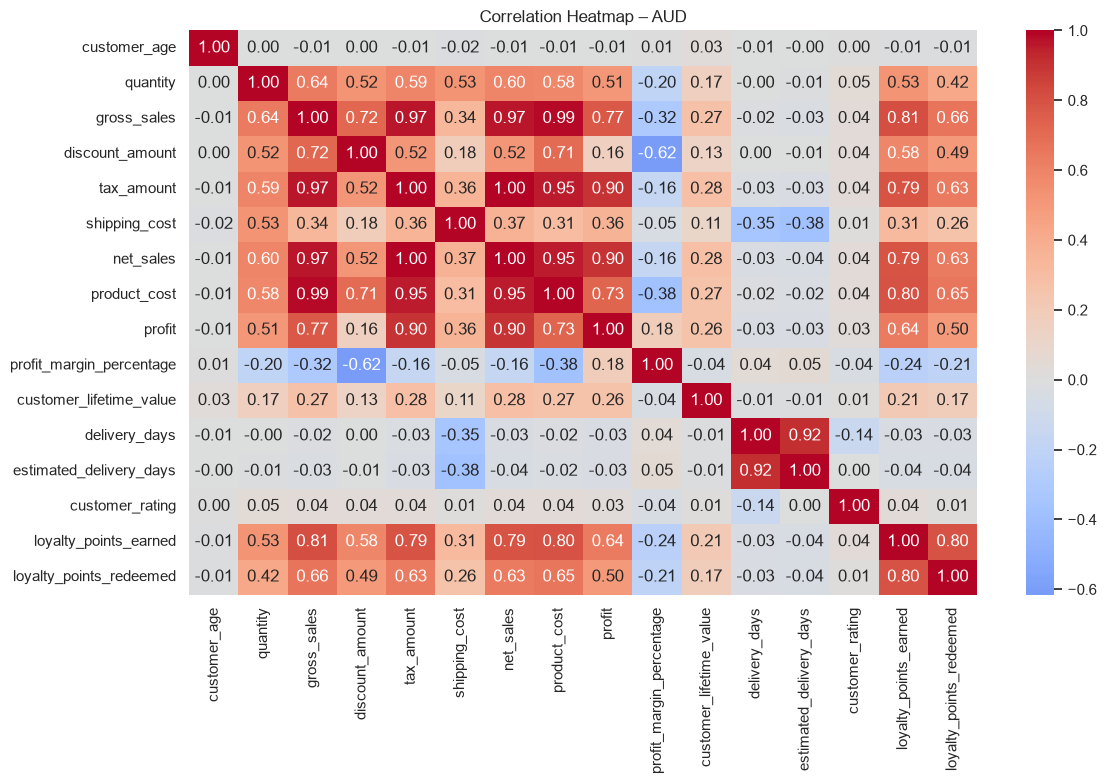


Correlation matrix – AED


,customer_age,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed
customer_age,1.00,0.00,0.01,0.02,0.00,-0.01,0.00,0.01,-0.00,-0.02,-0.01,0.00,-0.00,0.01,0.00,0.01
quantity,0.00,1.00,0.63,0.53,0.59,0.54,0.60,0.57,0.49,-0.20,0.16,0.01,-0.01,0.04,0.54,0.42
gross_sales,0.01,0.63,1.00,0.73,0.97,0.35,0.97,0.99,0.73,-0.33,0.28,0.01,0.01,0.04,0.84,0.67
discount_amount,0.02,0.53,0.73,1.00,0.54,0.20,0.54,0.73,0.12,-0.63,0.16,-0.00,-0.01,0.05,0.59,0.46
tax_amount,0.00,0.59,0.97,0.54,1.00,0.36,1.00,0.95,0.87,-0.18,0.29,0.02,0.01,0.04,0.82,0.66
shipping_cost,-0.01,0.54,0.35,0.20,0.36,1.00,0.38,0.32,0.35,-0.07,0.10,-0.32,-0.36,0.02,0.31,0.25
net_sales,0.00,0.60,0.97,0.54,1.00,0.38,1.00,0.95,0.87,-0.18,0.29,0.01,0.01,0.04,0.82,0.66
product_cost,0.01,0.57,0.99,0.73,0.95,0.32,0.95,1.00,0.67,-0.39,0.28,0.01,0.01,0.04,0.83,0.66
profit,-0.00,0.49,0.73,0.12,0.87,0.35,0.87,0.67,1.00,0.22,0.24,0.02,0.02,0.02,0.65,0.52
profit_margin_percentage,-0.02,-0.20,-0.33,-0.63,-0.18,-0.07,-0.18,-0.39,0.22,1.00,-0.06,0.03,0.04,-0.04,-0.24,-0.17


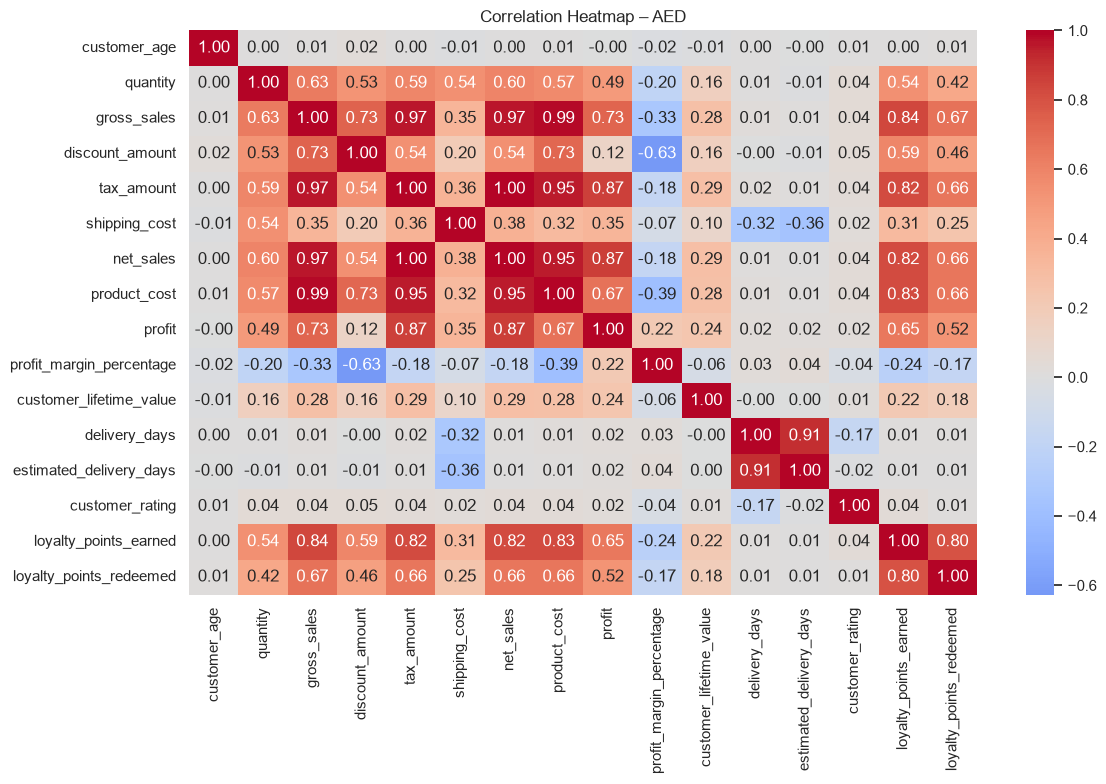

Interpret correlations as associations, not proof of causation.


In [ ]:
numeric_candidates = [
    "customer_age", "quantity", "gross_sales", "discount_amount",
    "tax_amount", "shipping_cost", "net_sales", "product_cost",
    "profit", "profit_margin_percentage", "customer_lifetime_value",
    "delivery_days", "estimated_delivery_days", "customer_rating",
    "loyalty_points_earned", "loyalty_points_redeemed"
]
numeric_cols = [c for c in numeric_candidates if c in sales_analysis.columns]

# Correlation is calculated separately within each currency because monetary values
# in different currencies are not directly comparable.
correlation_tables = {}
for curr in sales_analysis["currency"].dropna().unique():
    part = sales_analysis.loc[sales_analysis["currency"] == curr, numeric_cols]
    corr_data = part.corr(numeric_only=True)
    correlation_tables[curr] = corr_data
    print(f"\nCorrelation matrix – {curr}")
    display(corr_data)
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr_data, cmap="coolwarm", center=0, annot=True, fmt=".2f")
    plt.title(f"Correlation Heatmap – {curr}")
    plt.tight_layout()
    plt.show()

print("Interpret correlations as associations, not proof of causation.")

## 22. Statistical testing


### 22.1 Comparing profit between two order groups (Welch's t-test)

In [ ]:
if "is_repeat_customer" in sales_analysis.columns:
    for curr in sales_analysis["currency"].dropna().unique():
        part = sales_analysis[sales_analysis["currency"] == curr]
        a = part.loc[part["is_repeat_customer"] == True, "profit"].dropna()
        b = part.loc[part["is_repeat_customer"] == False, "profit"].dropna()
        if len(a) >= 2 and len(b) >= 2:
            result = stats.ttest_ind(a, b, equal_var=False)
            print(f"{curr}: repeat n={len(a)}, mean={a.mean():.2f}; "
                  f"non-repeat n={len(b)}, mean={b.mean():.2f}; "
                  f"t={result.statistic:.3f}, p={result.pvalue:.5g}")

USD: repeat n=82406, mean=507.46; non-repeat n=194, mean=544.41; t=-0.941, p=0.34802
EUR: repeat n=11560, mean=655.24; non-repeat n=33, mean=625.40; t=0.403, p=0.68971
INR: repeat n=5696, mean=631.26; non-repeat n=11, mean=545.57; t=0.552, p=0.59295
CAD: repeat n=6994, mean=574.92; non-repeat n=21, mean=669.94; t=-0.508, p=0.61714
GBP: repeat n=20185, mean=655.60; non-repeat n=50, mean=662.53; t=-0.089, p=0.92966
AUD: repeat n=6777, mean=543.37; non-repeat n=17, mean=585.14; t=-0.356, p=0.72669
AED: repeat n=4164, mean=487.30; non-repeat n=8, mean=418.02; t=0.718, p=0.49561


### 22.2 Comparing profit across sales channels (ANOVA)

In [ ]:
if "sales_channel" in sales_analysis.columns:
    for curr in sales_analysis["currency"].dropna().unique():
        part = sales_analysis[sales_analysis["currency"] == curr]
        groups = [
            g["profit"].dropna().values
            for _, g in part.groupby("sales_channel")
            if g["profit"].notna().sum() >= 2
        ]
        labels = [
            name for name, g in part.groupby("sales_channel")
            if g["profit"].notna().sum() >= 2
        ]
        if len(groups) >= 2:
            anova = stats.f_oneway(*groups)
            kruskal = stats.kruskal(*groups)
            print(f"\n{curr} | groups: {labels}")
            print("ANOVA F:", anova.statistic, "p:", anova.pvalue)
            print("Kruskal H:", kruskal.statistic, "p:", kruskal.pvalue)


USD | groups: ['Marketplace', 'Mobile App', 'Social Media', 'Website']
ANOVA F: 0.20150013320682214 p: 0.8954010094311344
Kruskal H: 1.283417966993284 p: 0.7330743601017721

EUR | groups: ['Marketplace', 'Mobile App', 'Social Media', 'Website']
ANOVA F: 1.3405760103145403 p: 0.2591835828962843
Kruskal H: 3.062943580044219 p: 0.38202196055263354

INR | groups: ['Marketplace', 'Mobile App', 'Social Media', 'Website']
ANOVA F: 0.23213212837587538 p: 0.8740468713699278
Kruskal H: 1.629761665317343 p: 0.6526605470655069

CAD | groups: ['Marketplace', 'Mobile App', 'Social Media', 'Website']
ANOVA F: 0.805449649150759 p: 0.49064373715355036
Kruskal H: 5.327801714962424 p: 0.14930851880229773

GBP | groups: ['Marketplace', 'Mobile App', 'Social Media', 'Website']
ANOVA F: 0.9686076334084143 p: 0.40639627702483305
Kruskal H: 1.833583111806174 p: 0.6076542847016626

AUD | groups: ['Marketplace', 'Mobile App', 'Social Media', 'Website']
ANOVA F: 3.6999184048640075 p: 0.011241203805714644
Kruska

## 23. A profit-leakage investigation table

This table identifies where recorded profit is negative. It is a prioritisation aid, not proof of the cause.

In [ ]:
leakage_by_channel = sales_analysis.groupby(
    ["currency", "sales_channel"], dropna=False
).agg(
    orders=("order_id", "count"),
    negative_profit_orders=("profit", lambda s: (s < 0).sum()),
    total_profit=("profit", "sum"),
    average_profit=("profit", "mean"),
    average_discount_amount=("discount_amount", "mean"),
    average_shipping_cost=("shipping_cost", "mean")
).reset_index()
leakage_by_channel["negative_profit_rate_pct"] = (
    leakage_by_channel["negative_profit_orders"] /
    leakage_by_channel["orders"] * 100
)
display(leakage_by_channel.sort_values(
    ["currency", "negative_profit_rate_pct"], ascending=[True, False]
))

,currency,sales_channel,orders,negative_profit_orders,total_profit,average_profit,average_discount_amount,average_shipping_cost,negative_profit_rate_pct
1,AED,Mobile App,1694,29,"843,670.40",498.03,258.88,31.09,1.71
2,AED,Social Media,413,6,"199,147.12",482.20,253.13,30.62,1.45
0,AED,Marketplace,613,8,"298,777.11",487.40,247.51,31.58,1.31
3,AED,Website,1452,17,"690,858.99",475.80,225.94,30.73,1.17
4,AUD,Marketplace,1060,13,"577,435.81",544.75,250.45,35.83,1.23
7,AUD,Website,2304,27,"1,314,687.32",570.61,246.96,35.08,1.17
5,AUD,Mobile App,2752,30,"1,443,452.70",524.51,235.43,34.60,1.09
6,AUD,Social Media,678,6,"356,819.32",526.28,246.90,35.19,0.88
11,CAD,Website,2447,18,"1,376,422.94",562.49,233.83,26.45,0.74
9,CAD,Mobile App,2842,20,"1,652,714.94",581.53,245.18,27.43,0.70


## 24. Evidence-based recommendations

Use the completed tables and charts to fill this template. Do not write a recommendation unless the analysis provides evidence for it.